In [1]:
# %% [markdown]
# # Análisis Exploratorio Profundo + Análisis Factorial Exploratorio (EFA)
# ## PISA 2022 - Preparación para LCA e IRT
# 
# **Objetivos de este notebook:**
# 1. Análisis descriptivo completo del dataset final
# 2. Análisis de correlaciones y relaciones entre variables
# 3. **Análisis Factorial Exploratorio (EFA) para reducción de dimensionalidad**
# 4. Identificación de variables latentes
# 5. Selección de variables para LCA
# 6. Preparación de ítems para IRT
# 7. Verificación de supuestos
#
# **Pre-requisito:**
# - Dataset final con imputación completada (mediana o MICE)

# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, pearsonr, spearmanr
import warnings
warnings.filterwarnings('ignore')

# Para Análisis Factorial
from sklearn.decomposition import FactorAnalysis, PCA
from sklearn.preprocessing import StandardScaler
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo

print("✓ Librerías cargadas")

# Si no tienes factor_analyzer:
# !pip install factor-analyzer

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10

✓ Librerías cargadas


### 1. Cargar dataset final ###

In [2]:
# %% [markdown]
# ## 1. Cargar dataset final

# %%
# Cargar tu dataset final (ajusta el nombre)
df = pd.read_csv('../data_collection_peru_csv/data_merge/COLLECT_COMP_PERU.csv')  # O dataset_imputado_mice.csv

print("="*80)
print("DATASET CARGADO")
print("="*80)
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"Memoria: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

# Verificar datos faltantes
missing_total = df.isna().sum().sum()
if missing_total > 0:
    print(f"⚠️ Aún hay {missing_total:,} valores faltantes")
else:
    print(f"✓ Dataset completamente imputado")

# Tipos de variables
print(f"\nTipos de variables:")
print(f"  Numéricas: {len(df.select_dtypes(include=[np.number]).columns)}")
print(f"  Categóricas: {len(df.select_dtypes(include=['object', 'category']).columns)}")

DATASET CARGADO
Dimensiones: 6,968 filas × 7147 columnas
Memoria: 911.23 MB
⚠️ Aún hay 38,662,715 valores faltantes

Tipos de variables:
  Numéricas: 4854
  Categóricas: 2293


### 2. Identificar variables clave automáticamente ###

In [3]:
def identificar_variables_pisa(df):
    """
    Identifica automáticamente variables clave de PISA
    """
    variables = {
        'ids': [],
        'pesos': [],
        'rendimiento': [],
        'socioeconomico': [],
        'demograficas': [],
        'actitudes': [],
        'escuela': [],
        'otras_numericas': [],
        'categoricas': []
    }
    
    # Patrones de búsqueda
    patrones = {
        'ids': ['CNTRYID', 'CNTSCHID', 'CNTSTUID', 'CNT'],
        'pesos': ['W_FSTUWT', 'WEIGHT', 'W_FST'],
        'rendimiento': ['PV1MATH', 'PV1READ', 'PV1SCIE', 'PV2', 'PV3', 'PV4', 'PV5'],
        'socioeconomico': ['ESCS', 'HOMEPOS', 'WEALTH', 'CULTPOSS', 'HEDRES', 'HISEI'],
        'demograficas': ['ST004D01T', 'GENDER', 'AGE', 'GRADE', 'IMMIG'],
        'actitudes': ['ANXTEST', 'MOTIVAT', 'BELONG', 'TEACHSUP', 'DISCLIMA', 'JOYREAD'],
        'escuela': ['SCHSIZE', 'STRATIO', 'SCHTYPE', 'CLSIZE', 'SC']
    }
    
    # Clasificar columnas
    for col in df.columns:
        col_upper = col.upper()
        clasificada = False
        
        for categoria, patterns in patrones.items():
            if any(pattern in col_upper for pattern in patterns):
                variables[categoria].append(col)
                clasificada = True
                break
        
        if not clasificada:
            if df[col].dtype in ['float64', 'int64']:
                variables['otras_numericas'].append(col)
            else:
                variables['categoricas'].append(col)
    
    return variables

vars_clasificadas = identificar_variables_pisa(df)

print("\n" + "="*80)
print("CLASIFICACIÓN AUTOMÁTICA DE VARIABLES")
print("="*80)

for categoria, vars_list in vars_clasificadas.items():
    if len(vars_list) > 0:
        print(f"\n{categoria.upper()}: {len(vars_list)} variables")
        print(f"  Primeras 5: {vars_list[:5]}")


CLASIFICACIÓN AUTOMÁTICA DE VARIABLES

IDS: 4 variables
  Primeras 5: ['CNT', 'CNTRYID', 'CNTSCHID', 'CNTSTUID']

PESOS: 83 variables
  Primeras 5: ['W_FSTUWT', 'W_FSTURWT1', 'W_FSTURWT2', 'W_FSTURWT3', 'W_FSTURWT4']

RENDIMIENTO: 63 variables
  Primeras 5: ['PV1MATH', 'PV2MATH', 'PV3MATH', 'PV4MATH', 'PV5MATH']

SOCIOECONOMICO: 3 variables
  Primeras 5: ['HISEI', 'HOMEPOS', 'ESCS']

DEMOGRAFICAS: 4 variables
  Primeras 5: ['ST004D01T', 'AGE', 'GRADE', 'IMMIG']

ACTITUDES: 2 variables
  Primeras 5: ['BELONG', 'TEACHSUP']

ESCUELA: 417 variables
  Primeras 5: ['CR545Q03SC', 'CR547Q07SC', 'CR558Q10SC', 'CR558Q02SC', 'CR561Q04SC']

OTRAS_NUMERICAS: 4605 variables
  Primeras 5: ['NatCen', 'SUBNATIO', 'CM033Q01TT', 'CM033Q01F', 'CM033Q01A']

CATEGORICAS: 1966 variables
  Primeras 5: ['CYC', 'STRATUM', 'REGION', 'OECD', 'ADMINMODE']


### 3. Estadísticas descriptivas completas ###

In [4]:
# %%
def estadisticas_completas(df, variables):
    """
    Genera estadísticas descriptivas completas
    """
    if len(variables) == 0:
        print("⚠️ No hay variables para analizar")
        return None
    
    # Filtrar solo numéricas
    vars_numericas = [v for v in variables if v in df.columns and df[v].dtype in ['float64', 'int64']]
    
    if len(vars_numericas) == 0:
        print("⚠️ No hay variables numéricas")
        return None
    
    stats_dict = {
        'Variable': [],
        'N': [],
        'N_Missing': [],
        'Pct_Missing': [],
        'Media': [],
        'Mediana': [],
        'DE': [],
        'CV': [],
        'Min': [],
        'Q1': [],
        'Q3': [],
        'Max': [],
        'Rango': [],
        'IQR': [],
        'Asimetría': [],
        'Curtosis': []
    }
    
    for var in vars_numericas[:50]:  # Limitar a 50 para no saturar
        data = df[var]
        data_clean = data.dropna()
        
        if len(data_clean) > 0:
            stats_dict['Variable'].append(var)
            stats_dict['N'].append(len(data_clean))
            stats_dict['N_Missing'].append(data.isna().sum())
            stats_dict['Pct_Missing'].append(data.isna().sum() / len(data) * 100)
            stats_dict['Media'].append(data_clean.mean())
            stats_dict['Mediana'].append(data_clean.median())
            stats_dict['DE'].append(data_clean.std())
            stats_dict['CV'].append(data_clean.std() / abs(data_clean.mean()) if data_clean.mean() != 0 else np.nan)
            stats_dict['Min'].append(data_clean.min())
            stats_dict['Q1'].append(data_clean.quantile(0.25))
            stats_dict['Q3'].append(data_clean.quantile(0.75))
            stats_dict['Max'].append(data_clean.max())
            stats_dict['Rango'].append(data_clean.max() - data_clean.min())
            stats_dict['IQR'].append(data_clean.quantile(0.75) - data_clean.quantile(0.25))
            stats_dict['Asimetría'].append(data_clean.skew())
            stats_dict['Curtosis'].append(data_clean.kurtosis())
    
    return pd.DataFrame(stats_dict)

# Estadísticas de rendimiento
print("\n" + "="*80)
print("ESTADÍSTICAS DESCRIPTIVAS - VARIABLES DE RENDIMIENTO")
print("="*80)

if len(vars_clasificadas['rendimiento']) > 0:
    stats_rendimiento = estadisticas_completas(df, vars_clasificadas['rendimiento'])
    if stats_rendimiento is not None:
        print(stats_rendimiento[['Variable', 'N', 'Media', 'DE', 'Min', 'Max']].to_string(index=False))
else:
    print("⚠️ No se encontraron variables de rendimiento")

# Estadísticas socioeconómicas
print("\n" + "="*80)
print("ESTADÍSTICAS DESCRIPTIVAS - VARIABLES SOCIOECONÓMICAS")
print("="*80)

if len(vars_clasificadas['socioeconomico']) > 0:
    stats_nse = estadisticas_completas(df, vars_clasificadas['socioeconomico'])
    if stats_nse is not None:
        print(stats_nse[['Variable', 'N', 'Media', 'DE', 'Min', 'Max']].to_string(index=False))


ESTADÍSTICAS DESCRIPTIVAS - VARIABLES DE RENDIMIENTO
  Variable    N      Media        DE     Min     Max
   PV1MATH 6968 393.943331 77.603134 178.146 727.576
   PV2MATH 6968 395.204718 77.990693 163.967 699.225
   PV3MATH 6968 394.055898 77.086754 145.529 692.668
   PV4MATH 6968 394.211655 78.392792 152.297 730.356
   PV5MATH 6968 394.157008 78.160911 150.438 682.276
   PV1READ 6968 411.055379 92.026447  73.004 699.871
   PV2READ 6968 411.141147 89.250759 113.874 700.146
   PV3READ 6968 411.148941 89.782285 118.720 719.673
   PV4READ 6968 410.142133 90.562061 111.266 741.997
   PV5READ 6968 411.178677 91.927088  79.476 705.454
   PV1SCIE 6968 410.835228 85.352398 124.045 761.870
   PV2SCIE 6968 410.719249 86.120741 124.945 706.773
   PV3SCIE 6968 410.358986 85.165972 128.235 704.239
   PV4SCIE 6968 411.653366 85.572589 103.302 740.196
   PV5SCIE 6968 409.601576 85.725307 135.318 709.349
   PV2MCCR 6968 394.100484 88.024412 103.854 710.340
   PV3MCCR 6968 394.390075 87.580927 100.050 

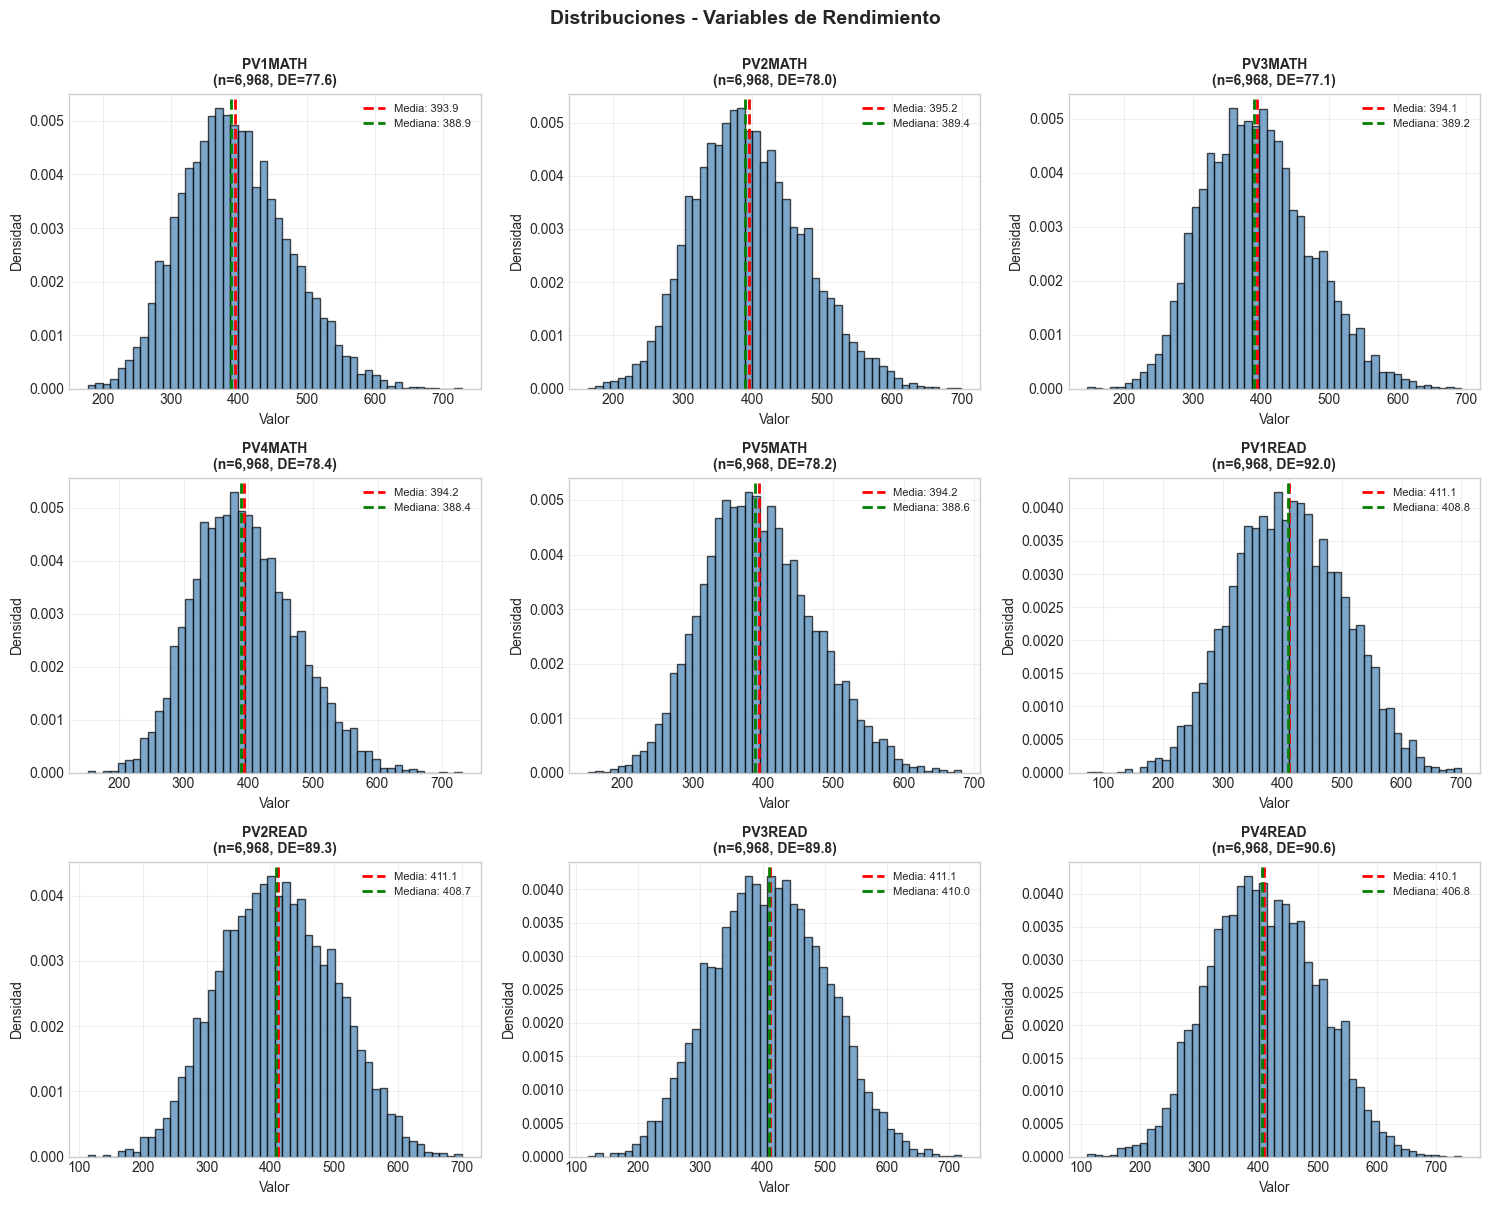

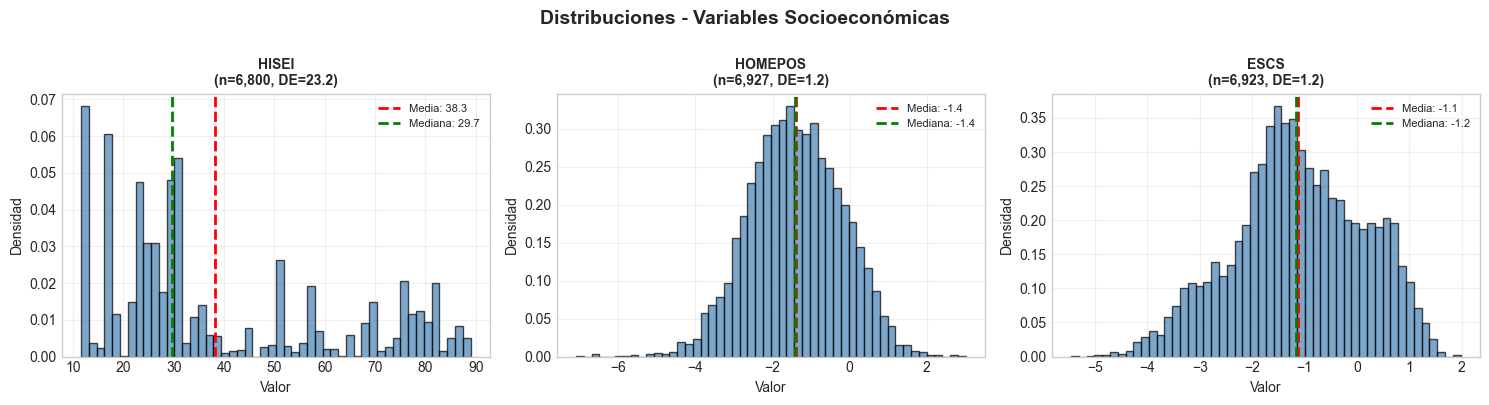

In [5]:
## 4. Visualización de distribuciones

# %%
def visualizar_distribuciones(df, variables, titulo="Distribuciones"):
    """
    Visualiza distribuciones de variables
    """
    # Filtrar numéricas
    vars_plot = [v for v in variables if v in df.columns and df[v].dtype in ['float64', 'int64']]
    vars_plot = vars_plot[:9]  # Máximo 9 para visualización 3x3
    
    if len(vars_plot) == 0:
        print("⚠️ No hay variables numéricas para graficar")
        return
    
    n_vars = len(vars_plot)
    n_cols = 3
    n_rows = (n_vars + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows))
    if n_vars == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    
    for idx, var in enumerate(vars_plot):
        data = df[var].dropna()
        
        if len(data) > 0:
            # Histograma con curva de densidad
            axes[idx].hist(data, bins=50, alpha=0.7, color='steelblue', 
                          edgecolor='black', density=True)
            
            # Líneas de referencia
            mean_val = data.mean()
            median_val = data.median()
            
            axes[idx].axvline(mean_val, color='red', linestyle='--', 
                             linewidth=2, label=f'Media: {mean_val:.1f}')
            axes[idx].axvline(median_val, color='green', linestyle='--',
                             linewidth=2, label=f'Mediana: {median_val:.1f}')
            
            axes[idx].set_title(f'{var}\n(n={len(data):,}, DE={data.std():.1f})', 
                               fontsize=10, fontweight='bold')
            axes[idx].set_xlabel('Valor')
            axes[idx].set_ylabel('Densidad')
            axes[idx].legend(fontsize=8)
            axes[idx].grid(alpha=0.3)
    
    # Ocultar ejes sobrantes
    for idx in range(n_vars, len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle(titulo, fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

# Visualizar rendimiento
if len(vars_clasificadas['rendimiento']) > 0:
    visualizar_distribuciones(df, vars_clasificadas['rendimiento'][:9], 
                             "Distribuciones - Variables de Rendimiento")

# Visualizar socioeconómicas
if len(vars_clasificadas['socioeconomico']) > 0:
    visualizar_distribuciones(df, vars_clasificadas['socioeconomico'][:9],
                             "Distribuciones - Variables Socioeconómicas")

In [6]:
# %% [markdown]
# ## 5. ANÁLISIS FACTORIAL EXPLORATORIO (EFA)
# ### 5.1. Preparación de datos para EFA

# %%
print("\n" + "="*80)
print("PREPARACIÓN PARA ANÁLISIS FACTORIAL EXPLORATORIO (EFA)")
print("="*80)

print("""
El EFA nos permite:
✓ Identificar variables latentes (factores)
✓ Reducir dimensionalidad
✓ Agrupar variables correlacionadas
✓ Preparar datos para IRT
✓ Entender estructura subyacente de los datos

Pasos:
1. Seleccionar variables apropiadas
2. Verificar supuestos (KMO, Bartlett)
3. Determinar número óptimo de factores
4. Extraer factores
5. Interpretar resultados
""")

def preparar_datos_efa(df, variables_candidatas, min_varianza=0.01):
    """
    Prepara datos para EFA
    
    Criterios:
    - Solo variables numéricas
    - Sin constantes (varianza > min_varianza)
    - Sin missing (ya deben estar imputadas)
    - Correlacionadas con al menos alguna otra variable
    """
    print("\n📊 Preparando datos para EFA...")
    
    # Filtrar numéricas
    vars_numericas = [v for v in variables_candidatas 
                      if v in df.columns and df[v].dtype in ['float64', 'int64']]
    
    print(f"   Variables numéricas iniciales: {len(vars_numericas)}")
    
    # Crear subset
    df_efa = df[vars_numericas].copy()
    
    # Eliminar variables constantes o casi constantes
    vars_validas = []
    for col in df_efa.columns:
        if df_efa[col].var() > min_varianza:
            vars_validas.append(col)
        else:
            print(f"   ⚠️ Eliminada {col}: varianza muy baja ({df_efa[col].var():.6f})")
    
    df_efa = df_efa[vars_validas]
    print(f"   Variables tras filtro de varianza: {len(df_efa.columns)}")
    
    # Verificar missing
    if df_efa.isna().sum().sum() > 0:
        print(f"   ⚠️ Hay {df_efa.isna().sum().sum()} valores faltantes")
        print("   Aplicando imputación de emergencia con mediana...")
        for col in df_efa.columns:
            if df_efa[col].isna().any():
                df_efa[col].fillna(df_efa[col].median(), inplace=True)
    
    print(f"\n✓ Dataset EFA preparado: {df_efa.shape}")
    
    return df_efa

# Seleccionar variables para EFA
# OPCIÓN 1: Usar variables socioeconómicas + actitudes (común en PISA)
vars_para_efa = (vars_clasificadas['socioeconomico'] + 
                 vars_clasificadas['actitudes'] + 
                 vars_clasificadas['otras_numericas'][:20])  # Agregar otras relevantes

# OPCIÓN 2: O definir manualmente variables de interés
# vars_para_efa = ['ESCS', 'HOMEPOS', 'WEALTH', 'CULTPOSS', ...]

print(f"\nVariables candidatas para EFA: {len(vars_para_efa)}")

df_efa = preparar_datos_efa(df, vars_para_efa)


PREPARACIÓN PARA ANÁLISIS FACTORIAL EXPLORATORIO (EFA)

El EFA nos permite:
✓ Identificar variables latentes (factores)
✓ Reducir dimensionalidad
✓ Agrupar variables correlacionadas
✓ Preparar datos para IRT
✓ Entender estructura subyacente de los datos

Pasos:
1. Seleccionar variables apropiadas
2. Verificar supuestos (KMO, Bartlett)
3. Determinar número óptimo de factores
4. Extraer factores
5. Interpretar resultados


Variables candidatas para EFA: 25

📊 Preparando datos para EFA...
   Variables numéricas iniciales: 25
   ⚠️ Eliminada NatCen: varianza muy baja (0.000000)
   ⚠️ Eliminada SUBNATIO: varianza muy baja (0.000000)
   ⚠️ Eliminada CM033Q01V: varianza muy baja (0.000000)
   ⚠️ Eliminada CM033Q01VS: varianza muy baja (0.000000)
   ⚠️ Eliminada CM474Q01V: varianza muy baja (0.000000)
   ⚠️ Eliminada CM474Q01VS: varianza muy baja (0.000000)
   ⚠️ Eliminada CM155Q02VS: varianza muy baja (0.003783)
   Variables tras filtro de varianza: 18
   ⚠️ Hay 81667 valores faltantes
   Ap

In [7]:
## 5.2. Verificación de supuestos para EFA
def verificar_supuestos_efa(df_efa):
    """
    Verifica supuestos necesarios para EFA:
    1. KMO (Kaiser-Meyer-Olkin): adecuación muestral
    2. Test de Bartlett: correlaciones significativas
    """
    print("\n" + "="*80)
    print("VERIFICACIÓN DE SUPUESTOS PARA EFA")
    print("="*80)
    
    # 1. Test de Bartlett
    print("\n1️⃣ TEST DE BARTLETT (esfericidad)")
    print("   H0: La matriz de correlación es una matriz identidad")
    print("   H1: Hay correlaciones significativas entre variables\n")
    
    try:
        chi_square_value, p_value = calculate_bartlett_sphericity(df_efa)
        print(f"   Chi-cuadrado: {chi_square_value:.2f}")
        print(f"   p-valor: {p_value:.2e}")
        
        if p_value < 0.05:
            print("   ✅ RESULTADO: Rechazamos H0 (p < 0.05)")
            print("      → Las variables están suficientemente correlacionadas")
            print("      → EFA es apropiado")
            bartlett_ok = True
        else:
            print("   ❌ RESULTADO: No rechazamos H0 (p >= 0.05)")
            print("      → Las variables NO están suficientemente correlacionadas")
            print("      → EFA NO es apropiado para estos datos")
            bartlett_ok = False
    except Exception as e:
        print(f"   ⚠️ Error en test de Bartlett: {e}")
        bartlett_ok = False
    
    # 2. KMO (Kaiser-Meyer-Olkin)
    print("\n2️⃣ ÍNDICE KMO (Kaiser-Meyer-Olkin)")
    print("   Mide la adecuación de los datos para análisis factorial\n")
    
    try:
        kmo_all, kmo_model = calculate_kmo(df_efa)
        
        print(f"   KMO global: {kmo_model:.3f}")
        
        # Interpretación
        if kmo_model >= 0.90:
            interpretacion = "Maravilloso"
            color = "✅"
        elif kmo_model >= 0.80:
            interpretacion = "Meritorio"
            color = "✅"
        elif kmo_model >= 0.70:
            interpretacion = "Mediano"
            color = "⚠️"
        elif kmo_model >= 0.60:
            interpretacion = "Mediocre"
            color = "⚠️"
        elif kmo_model >= 0.50:
            interpretacion = "Bajo"
            color = "❌"
        else:
            interpretacion = "Inaceptable"
            color = "❌"
        
        print(f"   {color} INTERPRETACIÓN: {interpretacion}")
        
        kmo_ok = kmo_model >= 0.60
        
        if kmo_ok:
            print("      → Los datos son adecuados para EFA")
        else:
            print("      → Los datos NO son adecuados para EFA")
            print("      → Considera eliminar variables problemáticas")
        
        # KMO por variable
        print(f"\n   Variables con KMO < 0.50 (problemáticas):")
        vars_problematicas = []
        for idx, (var, kmo_val) in enumerate(zip(df_efa.columns, kmo_all)):
            if kmo_val < 0.50:
                vars_problematicas.append(var)
                print(f"      • {var}: {kmo_val:.3f}")
        
        if len(vars_problematicas) == 0:
            print("      ✓ Ninguna variable es problemática")
        else:
            print(f"\n   ⚠️ Considera eliminar {len(vars_problematicas)} variables con KMO < 0.50")
        
    except Exception as e:
        print(f"   ⚠️ Error en cálculo de KMO: {e}")
        kmo_ok = False
        vars_problematicas = []
    
    # Resumen
    print("\n" + "="*80)
    print("RESUMEN DE SUPUESTOS:")
    print("="*80)
    print(f"   Test de Bartlett: {'✅ Apropiado' if bartlett_ok else '❌ No apropiado'}")
    print(f"   KMO global: {'✅ Adecuado' if kmo_ok else '❌ Inadecuado'} ({kmo_model:.3f})")
    
    if bartlett_ok and kmo_ok:
        print("\n   ✅ CONCLUSIÓN: Los datos son APROPIADOS para EFA")
        print("      → Puedes continuar con el análisis factorial")
    else:
        print("\n   ❌ CONCLUSIÓN: Los datos tienen problemas para EFA")
        print("      → Opciones:")
        print("        1. Eliminar variables problemáticas")
        print("        2. Seleccionar otro conjunto de variables")
        print("        3. Revisar la calidad de los datos")
    
    return {
        'bartlett_ok': bartlett_ok,
        'bartlett_p': p_value if 'p_value' in locals() else None,
        'kmo_ok': kmo_ok,
        'kmo_global': kmo_model if 'kmo_model' in locals() else None,
        'vars_problematicas': vars_problematicas if 'vars_problematicas' in locals() else []
    }

# Verificar supuestos
resultados_supuestos = verificar_supuestos_efa(df_efa)


VERIFICACIÓN DE SUPUESTOS PARA EFA

1️⃣ TEST DE BARTLETT (esfericidad)
   H0: La matriz de correlación es una matriz identidad
   H1: Hay correlaciones significativas entre variables

   Chi-cuadrado: 46685.48
   p-valor: 0.00e+00
   ✅ RESULTADO: Rechazamos H0 (p < 0.05)
      → Las variables están suficientemente correlacionadas
      → EFA es apropiado

2️⃣ ÍNDICE KMO (Kaiser-Meyer-Olkin)
   Mide la adecuación de los datos para análisis factorial

   KMO global: 0.498
   ❌ INTERPRETACIÓN: Inaceptable
      → Los datos NO son adecuados para EFA
      → Considera eliminar variables problemáticas

   Variables con KMO < 0.50 (problemáticas):
      • CM033Q01TT: 0.425
      • CM033Q01F: 0.398
      • CM033Q01A: 0.231
      • CM474Q01TT: 0.396
      • CM474Q01F: 0.311
      • CM474Q01A: 0.292
      • CM155Q01A: 0.487

   ⚠️ Considera eliminar 7 variables con KMO < 0.50

RESUMEN DE SUPUESTOS:
   Test de Bartlett: ✅ Apropiado
   KMO global: ❌ Inadecuado (0.498)

   ❌ CONCLUSIÓN: Los datos 

In [ ]:
## 5.3. Eliminar variables problemáticas (si es necesario)
if len(resultados_supuestos.get('vars_problematicas', [])) > 0:
    print("\n" + "="*80)
    print("LIMPIEZA DE VARIABLES PROBLEMÁTICAS")
    print("="*80)
    
    respuesta = input(f"\n¿Eliminar {len(resultados_supuestos['vars_problematicas'])} variables con KMO < 0.50? (s/n): ")
    
    if respuesta.lower() == 's':
        df_efa_limpio = df_efa.drop(columns=resultados_supuestos['vars_problematicas'])
        print(f"\n✓ Variables eliminadas: {len(resultados_supuestos['vars_problematicas'])}")
        print(f"✓ Variables restantes: {len(df_efa_limpio.columns)}")
        
        # Re-verificar supuestos
        print("\n Reverificando supuestos con datos limpios...")
        resultados_supuestos_limpio = verificar_supuestos_efa(df_efa_limpio)
        
        # Actualizar dataset
        df_efa = df_efa_limpio
    else:
        print("\n⚠️ Continuando con todas las variables")
        print("   Los resultados de EFA pueden no ser óptimos")

# %%


LIMPIEZA DE VARIABLES PROBLEMÁTICAS

⚠️ Continuando con todas las variables
   Los resultados de EFA pueden no ser óptimos



DETERMINACIÓN DEL NÚMERO ÓPTIMO DE FACTORES

1️⃣ CRITERIO DE KAISER (Eigenvalue > 1)
   Número de factores sugerido: 8
   Varianza explicada: 73.8%

   Primeros 10 eigenvalues:
      Factor 1: 2.789 (15.5% var, 15.5% acum)
      Factor 2: 2.468 (13.7% var, 29.2% acum)
      Factor 3: 1.846 (10.3% var, 39.5% acum)
      Factor 4: 1.782 (9.9% var, 49.4% acum)
      Factor 5: 1.164 (6.5% var, 55.8% acum)
      Factor 6: 1.119 (6.2% var, 62.0% acum)
      Factor 7: 1.107 (6.1% var, 68.2% acum)
      Factor 8: 1.009 (5.6% var, 73.8% acum)
      Factor 9: 0.991 (5.5% var, 79.3% acum)
      Factor 10: 0.866 (4.8% var, 84.1% acum)

2️⃣ CRITERIO DE VARIANZA EXPLICADA
   Factores para 70% varianza: 8
   Factores para 80% varianza: 10

3️⃣ SCREE PLOT (Gráfico de sedimentación)


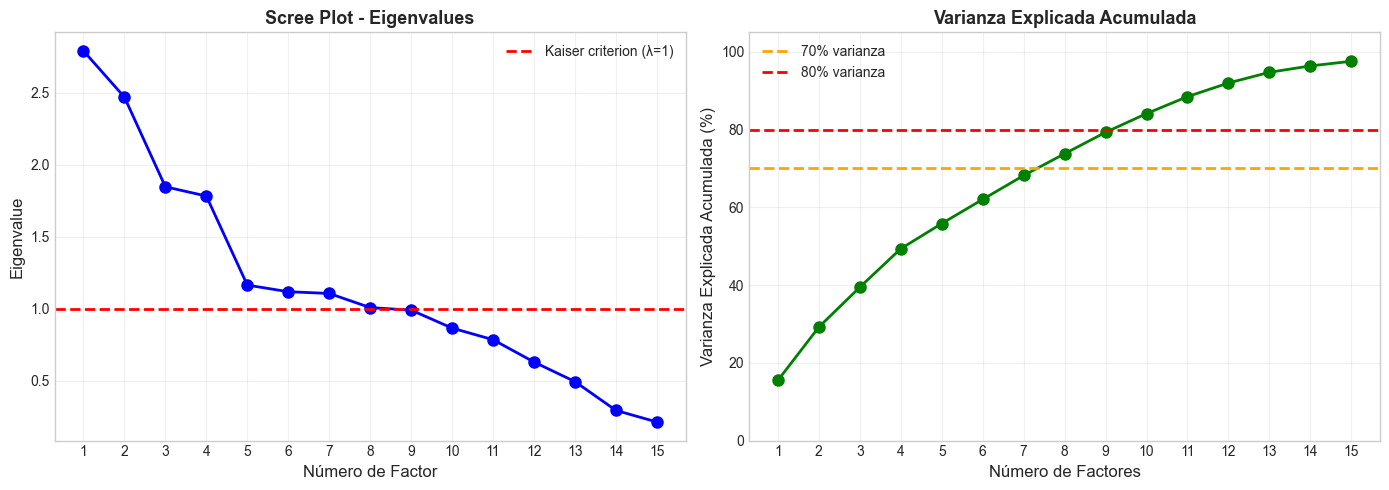

   → Busca el 'codo' donde los eigenvalues empiezan a aplanarse

4️⃣ ANÁLISIS PARALELO
   Comparando eigenvalues reales vs datos aleatorios...
   Factores sugeridos: 7


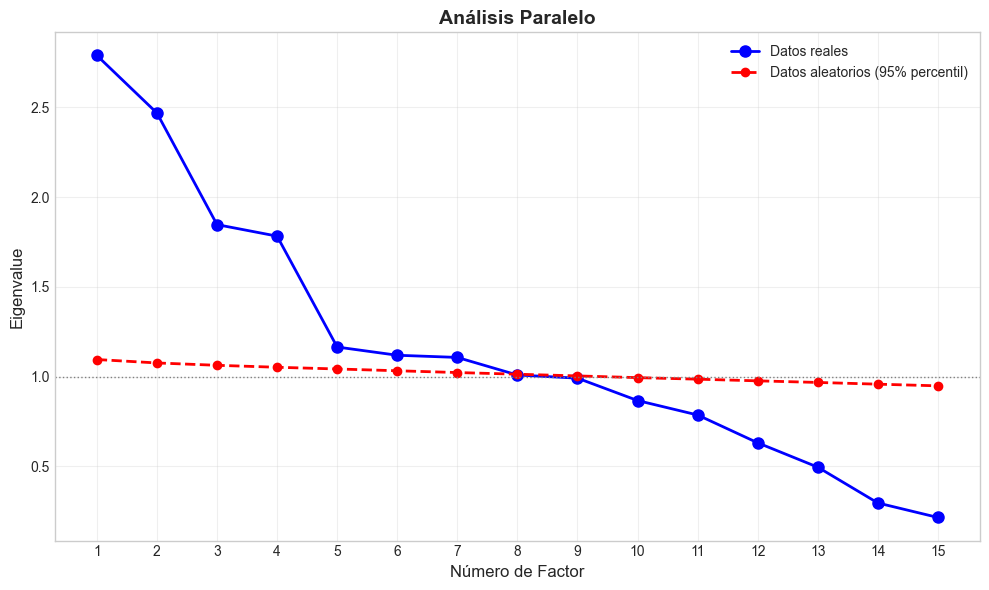


RECOMENDACIÓN FINAL

📊 Resumen de criterios:
   • Kaiser (λ > 1): 8 factores
   • Varianza 70%: 8 factores
   • Varianza 80%: 10 factores
   • Análisis Paralelo: 7 factores

✅ NÚMERO RECOMENDADO: 8 factores
   (mediana de los criterios)

💡 INTERPRETACIÓN:
   → Estructura factorial compleja (>6 factores)
   → Considera reducir número de variables o factores


In [10]:
# %% [markdown]
# ## 5.4. Determinar número óptimo de factores

# %%
def determinar_numero_factores(df_efa):
    """
    Determina el número óptimo de factores usando múltiples criterios
    """
    print("\n" + "="*80)
    print("DETERMINACIÓN DEL NÚMERO ÓPTIMO DE FACTORES")
    print("="*80)
    
    # Estandarizar datos
    scaler = StandardScaler()
    df_scaled = pd.DataFrame(
        scaler.fit_transform(df_efa),
        columns=df_efa.columns
    )
    
    # 1. Análisis de Componentes Principales (para eigenvalues)
    pca = PCA()
    pca.fit(df_scaled)
    
    eigenvalues = pca.explained_variance_
    var_explicada = pca.explained_variance_ratio_
    var_acumulada = np.cumsum(var_explicada)
    
    print("\n1️⃣ CRITERIO DE KAISER (Eigenvalue > 1)")
    n_kaiser = np.sum(eigenvalues > 1)
    print(f"   Número de factores sugerido: {n_kaiser}")
    print(f"   Varianza explicada: {var_acumulada[n_kaiser-1]*100:.1f}%")
    
    print("\n   Primeros 10 eigenvalues:")
    for i in range(min(10, len(eigenvalues))):
        print(f"      Factor {i+1}: {eigenvalues[i]:.3f} "
              f"({var_explicada[i]*100:.1f}% var, "
              f"{var_acumulada[i]*100:.1f}% acum)")
    
    # 2. Criterio de varianza explicada (70-80%)
    print("\n2️⃣ CRITERIO DE VARIANZA EXPLICADA")
    n_var70 = np.argmax(var_acumulada >= 0.70) + 1
    n_var80 = np.argmax(var_acumulada >= 0.80) + 1
    
    print(f"   Factores para 70% varianza: {n_var70}")
    print(f"   Factores para 80% varianza: {n_var80}")
    
    # 3. Scree Plot
    print("\n3️⃣ SCREE PLOT (Gráfico de sedimentación)")
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Gráfico 1: Eigenvalues
    n_factores = min(15, len(eigenvalues))
    axes[0].plot(range(1, n_factores+1), eigenvalues[:n_factores], 
                'bo-', linewidth=2, markersize=8)
    axes[0].axhline(y=1, color='r', linestyle='--', linewidth=2, label='Kaiser criterion (λ=1)')
    axes[0].set_xlabel('Número de Factor', fontsize=12)
    axes[0].set_ylabel('Eigenvalue', fontsize=12)
    axes[0].set_title('Scree Plot - Eigenvalues', fontweight='bold', fontsize=13)
    axes[0].grid(alpha=0.3)
    axes[0].legend()
    axes[0].set_xticks(range(1, n_factores+1))
    
    # Gráfico 2: Varianza explicada acumulada
    axes[1].plot(range(1, n_factores+1), var_acumulada[:n_factores]*100,
                'go-', linewidth=2, markersize=8)
    axes[1].axhline(y=70, color='orange', linestyle='--', linewidth=2, label='70% varianza')
    axes[1].axhline(y=80, color='red', linestyle='--', linewidth=2, label='80% varianza')
    axes[1].set_xlabel('Número de Factores', fontsize=12)
    axes[1].set_ylabel('Varianza Explicada Acumulada (%)', fontsize=12)
    axes[1].set_title('Varianza Explicada Acumulada', fontweight='bold', fontsize=13)
    axes[1].grid(alpha=0.3)
    axes[1].legend()
    axes[1].set_xticks(range(1, n_factores+1))
    axes[1].set_ylim([0, 105])
    
    plt.tight_layout()
    plt.show()
    
    print("   → Busca el 'codo' donde los eigenvalues empiezan a aplanarse")
    
    # 4. Análisis paralelo (más robusto)
    print("\n4️⃣ ANÁLISIS PARALELO")
    print("   Comparando eigenvalues reales vs datos aleatorios...")
    
    n_simulaciones = 100
    n_obs, n_vars = df_scaled.shape
    
    # Generar datos aleatorios y calcular eigenvalues
    eigenvalues_random = []
    for _ in range(n_simulaciones):
        random_data = np.random.normal(size=(n_obs, n_vars))
        pca_random = PCA()
        pca_random.fit(random_data)
        eigenvalues_random.append(pca_random.explained_variance_)
    
    eigenvalues_random_mean = np.mean(eigenvalues_random, axis=0)
    
    # Comparar
    n_paralelo = np.sum(eigenvalues > eigenvalues_random_mean)
    print(f"   Factores sugeridos: {n_paralelo}")
    
    # Gráfico de análisis paralelo
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, n_factores+1), eigenvalues[:n_factores], 
            'bo-', linewidth=2, markersize=8, label='Datos reales')
    plt.plot(range(1, n_factores+1), eigenvalues_random_mean[:n_factores],
            'ro--', linewidth=2, markersize=6, label='Datos aleatorios (95% percentil)')
    plt.axhline(y=1, color='gray', linestyle=':', linewidth=1)
    plt.xlabel('Número de Factor', fontsize=12)
    plt.ylabel('Eigenvalue', fontsize=12)
    plt.title('Análisis Paralelo', fontweight='bold', fontsize=14)
    plt.legend(fontsize=10)
    plt.grid(alpha=0.3)
    plt.xticks(range(1, n_factores+1))
    plt.tight_layout()
    plt.show()
    
    # 5. Recomendación final
    print("\n" + "="*80)
    print("RECOMENDACIÓN FINAL")
    print("="*80)
    
    # Promedio de criterios
    n_recomendado = int(np.median([n_kaiser, n_var70, n_paralelo]))
    
    print(f"\n📊 Resumen de criterios:")
    print(f"   • Kaiser (λ > 1): {n_kaiser} factores")
    print(f"   • Varianza 70%: {n_var70} factores")
    print(f"   • Varianza 80%: {n_var80} factores")
    print(f"   • Análisis Paralelo: {n_paralelo} factores")
    
    print(f"\n✅ NÚMERO RECOMENDADO: {n_recomendado} factores")
    print(f"   (mediana de los criterios)")
    
    print(f"\n💡 INTERPRETACIÓN:")
    if n_recomendado <= 3:
        print(f"   → Estructura factorial simple (2-3 factores)")
        print(f"   → Fácil de interpretar")
    elif n_recomendado <= 6:
        print(f"   → Estructura factorial moderada (4-6 factores)")
        print(f"   → Balance entre parsimonia y explicación")
    else:
        print(f"   → Estructura factorial compleja (>6 factores)")
        print(f"   → Considera reducir número de variables o factores")
    
    return {
        'n_kaiser': n_kaiser,
        'n_var70': n_var70,
        'n_var80': n_var80,
        'n_paralelo': n_paralelo,
        'n_recomendado': n_recomendado,
        'eigenvalues': eigenvalues,
        'var_explicada': var_explicada
    }

# Determinar número de factores
resultado_factores = determinar_numero_factores(df_efa)

In [11]:
## 5.5. Extracción de factores

# %%
# Elegir número de factores
n_factores = resultado_factores['n_recomendado']

print("\n" + "="*80)
print(f"EXTRACCIÓN DE {n_factores} FACTORES")
print("="*80)

# Permitir al usuario ajustar si lo desea
respuesta = input(f"\n¿Usar {n_factores} factores? (s/n, o ingresa otro número): ")

if respuesta.lower() == 'n':
    n_factores = int(input("Ingresa el número de factores deseado: "))
elif respuesta.isdigit():
    n_factores = int(respuesta)

print(f"\n→ Extrayendo {n_factores} factores...")

# Crear analizador factorial
fa = FactorAnalyzer(n_factors=n_factores, rotation='varimax', method='minres')

# Ajustar modelo
fa.fit(df_efa)

# Obtener cargas factoriales
loadings = pd.DataFrame(
    fa.loadings_,
    index=df_efa.columns,
    columns=[f'Factor_{i+1}' for i in range(n_factores)]
)

print(f"✓ Factores extraídos exitosamente")


EXTRACCIÓN DE 8 FACTORES

→ Extrayendo 8 factores...
✓ Factores extraídos exitosamente



CARGAS FACTORIALES

Cargas factoriales significativas (|carga| > 0.3):


Factor_1:
  ESCS                          :  1.022 +++
  HOMEPOS                       :  0.755 +++
  HISEI                         :  0.733 +++

Factor_2:
  CM033Q01TT                    :  0.956 +++
  CM033Q01F                     :  0.789 +++

Factor_3:
  CM155Q02TT                    :  0.859 +++
  CM155Q02A                     :  0.707 +++
  CM155Q02V                     :  0.373 +

Factor_4:
  CM155Q01TT                    :  0.858 +++
  CM155Q01A                     :  0.669 +++

Factor_5:
  CM474Q01F                     :  0.921 +++
  CM474Q01TT                    :  0.609 +++

Factor_6:
  CM155Q02F                     :  0.650 +++
  CM155Q02TT                    :  0.502 ++
  CM155Q01TT                    :  0.500 ++
  CM155Q01F                     :  0.412 ++
  CM155Q02V                     :  0.335 +

Factor_7:
  CM474Q01TT                    :  0.789 +++
  CM474Q01A                     :  0.748 +++

F

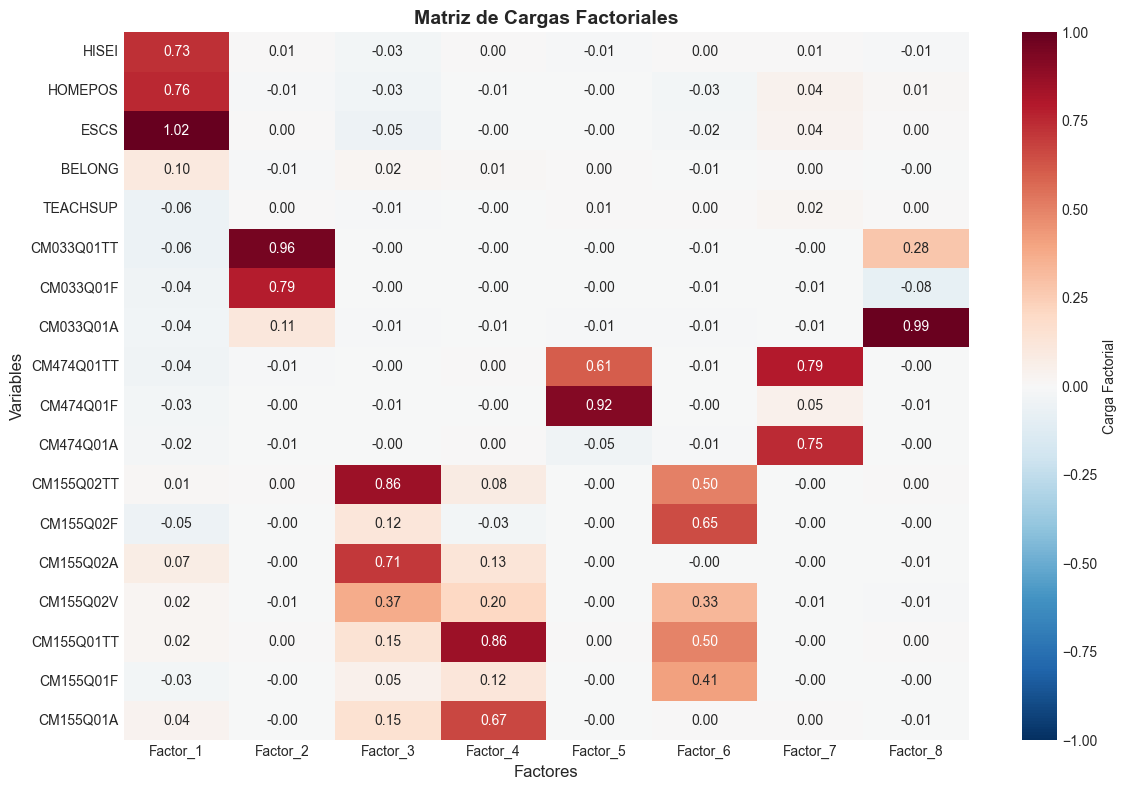


INTERPRETACIÓN DE FACTORES

Factor_1:
  Variable dominante: ESCS (carga: 1.022)
  Variables importantes (carga > 0.4): 3
    • ESCS: 1.022
    • HOMEPOS: 0.755
    • HISEI: 0.733

Factor_2:
  Variable dominante: CM033Q01TT (carga: 0.956)
  Variables importantes (carga > 0.4): 2
    • CM033Q01TT: 0.956
    • CM033Q01F: 0.789

Factor_3:
  Variable dominante: CM155Q02TT (carga: 0.859)
  Variables importantes (carga > 0.4): 2
    • CM155Q02TT: 0.859
    • CM155Q02A: 0.707

Factor_4:
  Variable dominante: CM155Q01TT (carga: 0.858)
  Variables importantes (carga > 0.4): 2
    • CM155Q01TT: 0.858
    • CM155Q01A: 0.669

Factor_5:
  Variable dominante: CM474Q01F (carga: 0.921)
  Variables importantes (carga > 0.4): 2
    • CM474Q01F: 0.921
    • CM474Q01TT: 0.609

Factor_6:
  Variable dominante: CM155Q02F (carga: 0.650)
  Variables importantes (carga > 0.4): 4
    • CM155Q02F: 0.650
    • CM155Q02TT: 0.502
    • CM155Q01TT: 0.500
    • CM155Q01F: 0.412

Factor_7:
  Variable dominante: CM474Q0

In [12]:
# %% [markdown]
# ## 5.6. Visualización de cargas factoriales

# %%
def visualizar_cargas_factoriales(loadings, umbral=0.3):
    """
    Visualiza las cargas factoriales
    """
    print("\n" + "="*80)
    print("CARGAS FACTORIALES")
    print("="*80)
    
    # Mostrar cargas significativas (>umbral)
    print(f"\nCargas factoriales significativas (|carga| > {umbral}):\n")
    
    for factor in loadings.columns:
        print(f"\n{factor}:")
        cargas_sig = loadings[loadings[factor].abs() > umbral][factor].sort_values(ascending=False)
        
        if len(cargas_sig) > 0:
            for var, carga in cargas_sig.items():
                print(f"  {var:30s}: {carga:6.3f} {'+++' if carga > 0.6 else '++' if carga > 0.4 else '+'}")
        else:
            print("  (No hay cargas significativas)")
    
    # Heatmap de cargas
    plt.figure(figsize=(12, max(8, len(loadings)*0.3)))
    sns.heatmap(loadings, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
                vmin=-1, vmax=1, cbar_kws={'label': 'Carga Factorial'})
    plt.title('Matriz de Cargas Factoriales', fontweight='bold', fontsize=14)
    plt.xlabel('Factores', fontsize=12)
    plt.ylabel('Variables', fontsize=12)
    plt.tight_layout()
    plt.show()
    
    # Identificar variable dominante por factor
    print("\n" + "="*80)
    print("INTERPRETACIÓN DE FACTORES")
    print("="*80)
    
    for factor in loadings.columns:
        var_dominante = loadings[factor].abs().idxmax()
        carga_max = loadings.loc[var_dominante, factor]
        
        print(f"\n{factor}:")
        print(f"  Variable dominante: {var_dominante} (carga: {carga_max:.3f})")
        
        # Variables con carga > 0.4
        vars_altas = loadings[loadings[factor].abs() > 0.4][factor].abs().sort_values(ascending=False)
        print(f"  Variables importantes (carga > 0.4): {len(vars_altas)}")
        for var in vars_altas.index[:5]:  # Top 5
            print(f"    • {var}: {loadings.loc[var, factor]:.3f}")

visualizar_cargas_factoriales(loadings, umbral=0.3)


COMUNALIDADES Y VARIANZA EXPLICADA

1️⃣ COMUNALIDADES (Top 10 y Bottom 5):

Variables mejor explicadas por los factores:
  Variable  Comunalidad  Varianza_Unica
      ESCS     1.047730       -0.047730
CM155Q01TT     1.008129       -0.008129
CM155Q02TT     0.996782        0.003218
CM033Q01TT     0.995554        0.004446
CM474Q01TT     0.995253        0.004747
 CM033Q01A     0.985024        0.014976
 CM474Q01F     0.852315        0.147685
 CM033Q01F     0.630926        0.369074
   HOMEPOS     0.574518        0.425482
 CM474Q01A     0.561911        0.438089

Variables peor explicadas por los factores:
 Variable  Comunalidad  Varianza_Unica
CM155Q02F     0.440364        0.559636
CM155Q02V     0.293028        0.706972
CM155Q01F     0.188557        0.811443
   BELONG     0.010772        0.989228
 TEACHSUP     0.003668        0.996332

⚠️ 4 variables con comunalidad < 0.3:
   Estas variables no están bien representadas por los factores
   Considera eliminarlas o agregar más factores

2️⃣ VAR

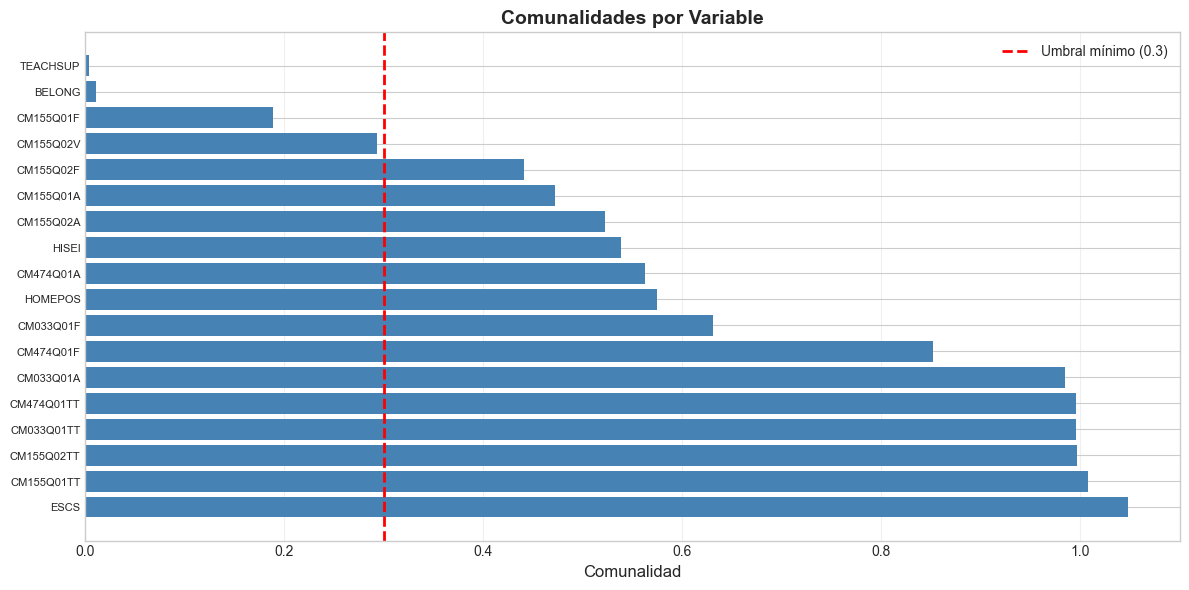

In [13]:
# %% [markdown]
# ## 5.7. Comunalidades y varianza explicada por factor

# %%
def analizar_comunalidades(fa, loadings, df_efa):
    """
    Analiza comunalidades y varianza explicada
    """
    print("\n" + "="*80)
    print("COMUNALIDADES Y VARIANZA EXPLICADA")
    print("="*80)
    
    # Comunalidades (proporción de varianza explicada de cada variable)
    comunalidades = fa.get_communalities()
    
    df_comunalidades = pd.DataFrame({
        'Variable': df_efa.columns,
        'Comunalidad': comunalidades,
        'Varianza_Unica': 1 - comunalidades
    }).sort_values('Comunalidad', ascending=False)
    
    print("\n1️⃣ COMUNALIDADES (Top 10 y Bottom 5):")
    print("\nVariables mejor explicadas por los factores:")
    print(df_comunalidades.head(10).to_string(index=False))
    
    print("\nVariables peor explicadas por los factores:")
    print(df_comunalidades.tail(5).to_string(index=False))
    
    # Identificar variables con baja comunalidad
    vars_baja_comunalidad = df_comunalidades[df_comunalidades['Comunalidad'] < 0.3]
    if len(vars_baja_comunalidad) > 0:
        print(f"\n⚠️ {len(vars_baja_comunalidad)} variables con comunalidad < 0.3:")
        print("   Estas variables no están bien representadas por los factores")
        print("   Considera eliminarlas o agregar más factores")
    
    # Varianza explicada por cada factor
    var_por_factor = fa.get_factor_variance()
    
    print("\n2️⃣ VARIANZA EXPLICADA POR FACTOR:")
    print(f"\n{'Factor':<15} {'SS Loadings':<15} {'% Varianza':<15} {'% Acumulado':<15}")
    print("-" * 60)
    
    for i in range(len(var_por_factor[0])):
        print(f"Factor_{i+1:<8} {var_por_factor[0][i]:>10.3f} {var_por_factor[1][i]*100:>13.2f}% {var_por_factor[2][i]*100:>13.2f}%")
    
    # Visualización de comunalidades
    plt.figure(figsize=(12, 6))
    plt.barh(range(len(df_comunalidades)), df_comunalidades['Comunalidad'], color='steelblue')
    plt.yticks(range(len(df_comunalidades)), df_comunalidades['Variable'], fontsize=8)
    plt.axvline(x=0.3, color='red', linestyle='--', linewidth=2, label='Umbral mínimo (0.3)')
    plt.xlabel('Comunalidad', fontsize=12)
    plt.title('Comunalidades por Variable', fontweight='bold', fontsize=14)
    plt.legend()
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return df_comunalidades, var_por_factor

df_comunalidades, var_por_factor = analizar_comunalidades(fa, loadings, df_efa)


PUNTUACIONES FACTORIALES

✓ Calculadas puntuaciones factoriales para 6968 observaciones

Primeras 5 observaciones:
   Factor_1  Factor_2  Factor_3  Factor_4  Factor_5  Factor_6  Factor_7  \
0 -0.679188 -0.079194 -0.047632 -0.022045 -0.083112 -0.043000 -0.085928   
1 -0.268212 -0.063179 -0.060795 -0.024202  3.632541 -0.022372  2.062761   
2 -1.285460 -0.110807 -0.013565  0.003297 -0.101249 -0.080953 -0.101609   
3 -2.232035 -0.153316  0.013394  0.053806 -0.117372 -0.080036 -0.149682   
4  1.025158  0.011979 -0.106316 -0.087619 -0.042099  0.028731 -0.030074   

   Factor_8  
0 -0.166524  
1 -0.106149  
2 -0.183414  
3 -0.217566  
4 -0.113139  

Estadísticas de los factores:
           Factor_1      Factor_2      Factor_3      Factor_4      Factor_5  \
count  6.968000e+03  6.968000e+03  6.968000e+03  6.968000e+03  6.968000e+03   
mean  -1.264456e-16 -1.509190e-16  4.078891e-17 -1.182878e-16 -1.968065e-16   
std    1.046811e+00  9.970161e-01  9.548271e-01  9.665430e-01  9.330804e-01   
mi

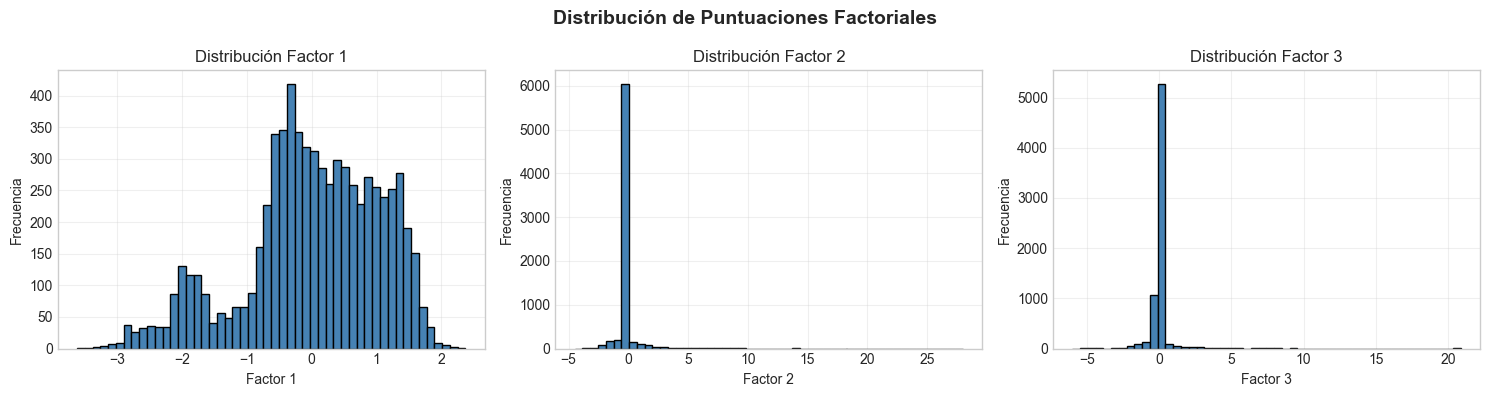


✓ Puntuaciones factoriales agregadas al dataset principal
  Nuevas columnas: ['Factor_1', 'Factor_2', 'Factor_3', 'Factor_4', 'Factor_5', 'Factor_6', 'Factor_7', 'Factor_8']


In [14]:
# %% [markdown]
# ## 5.8. Puntuaciones factoriales (Factor Scores)

# %%
# Calcular puntuaciones factoriales para cada observación
factor_scores = fa.transform(df_efa)

# Crear DataFrame con scores
df_factor_scores = pd.DataFrame(
    factor_scores,
    columns=[f'Factor_{i+1}' for i in range(n_factores)],
    index=df_efa.index
)

print("\n" + "="*80)
print("PUNTUACIONES FACTORIALES")
print("="*80)

print(f"\n✓ Calculadas puntuaciones factoriales para {len(df_factor_scores)} observaciones")
print(f"\nPrimeras 5 observaciones:")
print(df_factor_scores.head())

print(f"\nEstadísticas de los factores:")
print(df_factor_scores.describe())

# Visualizar distribución de factores
fig, axes = plt.subplots(1, min(3, n_factores), figsize=(15, 4))
if n_factores == 1:
    axes = [axes]

for i in range(min(3, n_factores)):
    axes[i].hist(df_factor_scores[f'Factor_{i+1}'], bins=50, color='steelblue', edgecolor='black')
    axes[i].set_xlabel(f'Factor {i+1}')
    axes[i].set_ylabel('Frecuencia')
    axes[i].set_title(f'Distribución Factor {i+1}')
    axes[i].grid(alpha=0.3)

plt.suptitle('Distribución de Puntuaciones Factoriales', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Agregar scores al dataset original
for col in df_factor_scores.columns:
    df[col] = df_factor_scores[col]

print(f"\n✓ Puntuaciones factoriales agregadas al dataset principal")
print(f"  Nuevas columnas: {list(df_factor_scores.columns)}")

In [15]:
# ## 5.9. Interpretación y nombramiento de factores

# %%
print("\n" + "="*80)
print("GUÍA PARA INTERPRETAR Y NOMBRAR FACTORES")
print("="*80)

print("""
Para cada factor, identifica:

1. ¿Qué variables tienen las cargas más altas (>0.4)?
2. ¿Qué tienen en común conceptualmente estas variables?
3. ¿Qué constructo latente representan?

Ejemplos de factores comunes en PISA:

• Factor Socioeconómico:
  - ESCS, HOMEPOS, WEALTH, CULTPOSS
  - Representa el estatus socioeconómico familiar

• Factor de Recursos Educativos:
  - HEDRES, libros en casa, acceso a tecnología
  - Representa recursos para el aprendizaje

• Factor Motivacional:
  - MOTIVAT, JOYREAD, actitudes hacia el estudio
  - Representa motivación intrínseca

• Factor de Clima Escolar:
  - DISCLIMA, TEACHSUP, BELONG
  - Representa ambiente de aprendizaje

Ahora analiza TUS factores con las cargas mostradas arriba.
""")

# Crear tabla para nombrar factores
print("\n📝 NOMBRA TUS FACTORES:")
nombres_factores = {}

for i in range(n_factores):
    factor_name = f'Factor_{i+1}'
    print(f"\n{factor_name}:")
    print(f"  Variables principales:")
    
    # Mostrar top 5 variables
    top_vars = loadings[factor_name].abs().sort_values(ascending=False).head(5)
    for var, carga in top_vars.items():
        print(f"    • {var}: {loadings.loc[var, factor_name]:.3f}")
    
    nombre = input(f"\n  ¿Cómo nombrarías este factor? (ej: 'NSE_Familiar'): ")
    if nombre.strip():
        nombres_factores[factor_name] = nombre
    else:
        nombres_factores[factor_name] = factor_name

# Renombrar columnas en el dataset
df.rename(columns=nombres_factores, inplace=True)
loadings.rename(columns=nombres_factores, inplace=True)
df_factor_scores.rename(columns=nombres_factores, inplace=True)

print("\n✓ Factores renombrados:")
for old, new in nombres_factores.items():
    print(f"  {old} → {new}")


GUÍA PARA INTERPRETAR Y NOMBRAR FACTORES

Para cada factor, identifica:

1. ¿Qué variables tienen las cargas más altas (>0.4)?
2. ¿Qué tienen en común conceptualmente estas variables?
3. ¿Qué constructo latente representan?

Ejemplos de factores comunes en PISA:

• Factor Socioeconómico:
  - ESCS, HOMEPOS, WEALTH, CULTPOSS
  - Representa el estatus socioeconómico familiar

• Factor de Recursos Educativos:
  - HEDRES, libros en casa, acceso a tecnología
  - Representa recursos para el aprendizaje

• Factor Motivacional:
  - MOTIVAT, JOYREAD, actitudes hacia el estudio
  - Representa motivación intrínseca

• Factor de Clima Escolar:
  - DISCLIMA, TEACHSUP, BELONG
  - Representa ambiente de aprendizaje

Ahora analiza TUS factores con las cargas mostradas arriba.


📝 NOMBRA TUS FACTORES:

Factor_1:
  Variables principales:
    • ESCS: 1.022
    • HOMEPOS: 0.755
    • HISEI: 0.733
    • BELONG: 0.101
    • CM155Q02A: 0.074

Factor_2:
  Variables principales:
    • CM033Q01TT: 0.956
    • C


CORRELACIONES: FACTORES vs RENDIMIENTO ACADÉMICO

Tabla de correlaciones:
  Factor Variable_Rendimiento  Correlación       p-valor Significativa
Factor_1              PV1MATH     0.386072 1.760684e-246             ✓
Factor_1              PV1READ     0.383990 1.247293e-243             ✓
Factor_1              PV1SCIE     0.366212 3.953614e-220             ✓
Factor_2              PV1MATH    -0.004925  6.810404e-01             ✗
Factor_2              PV1READ    -0.001945  8.710633e-01             ✗
Factor_2              PV1SCIE    -0.000942  9.373257e-01             ✗
Factor_3              PV1MATH    -0.011387  3.419060e-01             ✗
Factor_3              PV1READ    -0.013630  2.552961e-01             ✗
Factor_3              PV1SCIE    -0.006916  5.637791e-01             ✗
Factor_4              PV1MATH     0.005840  6.259434e-01             ✗
Factor_4              PV1READ     0.016049  1.803913e-01             ✗
Factor_4              PV1SCIE     0.019282  1.075219e-01             ✗
Fa

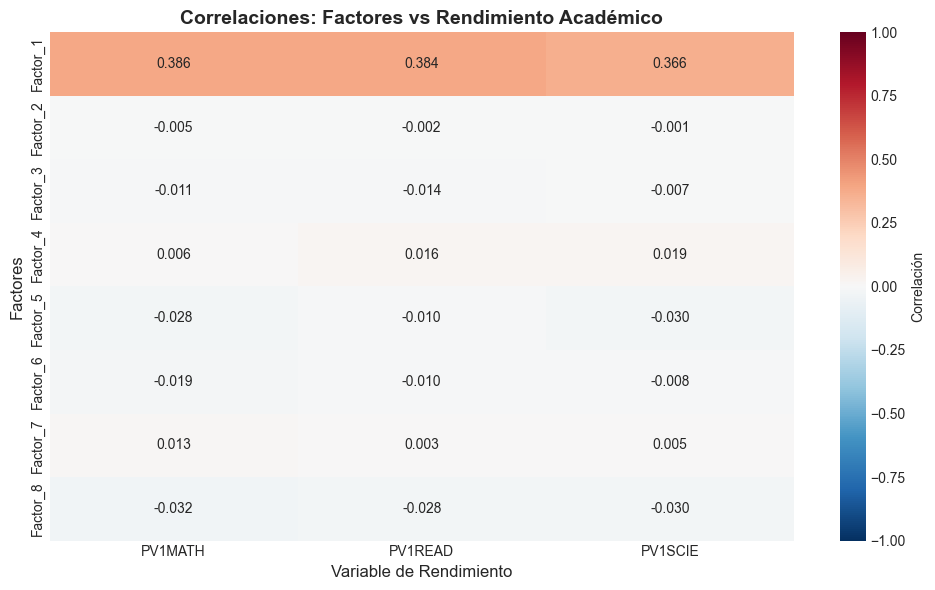


📊 FACTORES MÁS PREDICTIVOS DEL RENDIMIENTO:
  Factor_1: r_promedio = 0.379 (±0.011)
  Factor_4: r_promedio = 0.014 (±0.007)
  Factor_7: r_promedio = 0.007 (±0.005)
  Factor_2: r_promedio = -0.003 (±0.002)
  Factor_3: r_promedio = -0.011 (±0.003)
  Factor_6: r_promedio = -0.012 (±0.006)
  Factor_5: r_promedio = -0.023 (±0.011)
  Factor_8: r_promedio = -0.030 (±0.002)


In [16]:
# %% [markdown]
# ## 6. Correlaciones entre factores y rendimiento

# %%
def analizar_correlaciones_factores_rendimiento(df, factores, vars_rendimiento):
    """
    Analiza correlación entre factores extraídos y rendimiento académico
    """
    print("\n" + "="*80)
    print("CORRELACIONES: FACTORES vs RENDIMIENTO ACADÉMICO")
    print("="*80)
    
    # Filtrar variables de rendimiento disponibles
    vars_rend = [v for v in vars_rendimiento if v in df.columns]
    
    if len(vars_rend) == 0:
        print("⚠️ No se encontraron variables de rendimiento")
        return None
    
    # Tomar solo primer PV de cada dominio para simplificar
    vars_rend_principales = []
    for dominio in ['MATH', 'READ', 'SCIE']:
        pv1 = [v for v in vars_rend if 'PV1' in v and dominio in v]
        if pv1:
            vars_rend_principales.append(pv1[0])
    
    if len(vars_rend_principales) == 0:
        vars_rend_principales = vars_rend[:3]  # Tomar primeras 3
    
    # Calcular correlaciones
    correlaciones = []
    for factor in factores:
        if factor in df.columns:
            for var_rend in vars_rend_principales:
                if var_rend in df.columns:
                    data = df[[factor, var_rend]].dropna()
                    if len(data) > 0:
                        corr, pval = pearsonr(data[factor], data[var_rend])
                        correlaciones.append({
                            'Factor': factor,
                            'Variable_Rendimiento': var_rend,
                            'Correlación': corr,
                            'p-valor': pval,
                            'Significativa': '✓' if pval < 0.05 else '✗'
                        })
    
    if len(correlaciones) == 0:
        print("⚠️ No se pudieron calcular correlaciones")
        return None
    
    df_corr = pd.DataFrame(correlaciones)
    
    print("\nTabla de correlaciones:")
    print(df_corr.to_string(index=False))
    
    # Visualización
    pivot_corr = df_corr.pivot(index='Factor', columns='Variable_Rendimiento', values='Correlación')
    
    plt.figure(figsize=(10, max(6, len(factores)*0.5)))
    sns.heatmap(pivot_corr, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
                vmin=-1, vmax=1, cbar_kws={'label': 'Correlación'})
    plt.title('Correlaciones: Factores vs Rendimiento Académico', 
             fontweight='bold', fontsize=14)
    plt.xlabel('Variable de Rendimiento', fontsize=12)
    plt.ylabel('Factores', fontsize=12)
    plt.tight_layout()
    plt.show()
    
    # Identificar factores más predictivos
    print("\n📊 FACTORES MÁS PREDICTIVOS DEL RENDIMIENTO:")
    correlaciones_promedio = df_corr.groupby('Factor')['Correlación'].agg(['mean', 'std'])
    correlaciones_promedio = correlaciones_promedio.sort_values('mean', ascending=False)
    
    for factor, row in correlaciones_promedio.iterrows():
        print(f"  {factor}: r_promedio = {row['mean']:.3f} (±{row['std']:.3f})")
    
    return df_corr

# Analizar correlaciones
factores_extraidos = list(nombres_factores.values())
correlaciones_factores = analizar_correlaciones_factores_rendimiento(
    df, factores_extraidos, vars_clasificadas['rendimiento']
)

In [17]:
# %% [markdown]
# ## 7. Selección de variables para LCA basada en EFA

# %%
print("\n" + "="*80)
print("SELECCIÓN DE VARIABLES PARA LCA (Latent Class Analysis)")
print("="*80)

print("""
Con base en el EFA, puedes seleccionar variables para LCA de dos formas:

OPCIÓN 1: Usar las puntuaciones factoriales
   • Ventaja: Reduce dimensionalidad drásticamente
   • Usa los factores como variables continuas en LCA
   • Ejemplo: Si tienes 3 factores, LCA trabajará con 3 variables

OPCIÓN 2: Usar variables originales bien representadas
   • Toma variables con alta comunalidad (>0.5)
   • Selecciona las más representativas de cada factor
   • Mantiene interpretabilidad de variables originales

OPCIÓN 3: Híbrido
   • Factores + algunas variables clave originales
   • Balance entre parsimonia y riqueza de información
""")

# Opción 1: Factores
print("\n1️⃣ OPCIÓN FACTORES:")
print(f"   Variables para LCA: {factores_extraidos}")
print(f"   Total: {len(factores_extraidos)} variables")

# Opción 2: Variables originales bien representadas
print("\n2️⃣ OPCIÓN VARIABLES ORIGINALES:")
vars_alta_comunalidad = df_comunalidades[df_comunalidades['Comunalidad'] > 0.5]['Variable'].tolist()
print(f"   Variables con comunalidad > 0.5: {len(vars_alta_comunalidad)}")
print(f"   Primeras 15: {vars_alta_comunalidad[:15]}")

# Opción 3: Seleccionar top variable por factor
print("\n3️⃣ OPCIÓN REPRESENTATIVAS POR FACTOR:")
vars_representativas = []
for factor in factores_extraidos:
    var_top = loadings[factor].abs().idxmax()
    vars_representativas.append(var_top)
    print(f"   {factor}: {var_top} (carga: {loadings.loc[var_top, factor]:.3f})")

print(f"\n   Total variables representativas: {len(vars_representativas)}")

# Guardar selecciones
selecciones_lca = {
    'factores': factores_extraidos,
    'alta_comunalidad': vars_alta_comunalidad,
    'representativas': vars_representativas
}

print("\n💾 Variables guardadas para decisión posterior de LCA")


SELECCIÓN DE VARIABLES PARA LCA (Latent Class Analysis)

Con base en el EFA, puedes seleccionar variables para LCA de dos formas:

OPCIÓN 1: Usar las puntuaciones factoriales
   • Ventaja: Reduce dimensionalidad drásticamente
   • Usa los factores como variables continuas en LCA
   • Ejemplo: Si tienes 3 factores, LCA trabajará con 3 variables

OPCIÓN 2: Usar variables originales bien representadas
   • Toma variables con alta comunalidad (>0.5)
   • Selecciona las más representativas de cada factor
   • Mantiene interpretabilidad de variables originales

OPCIÓN 3: Híbrido
   • Factores + algunas variables clave originales
   • Balance entre parsimonia y riqueza de información


1️⃣ OPCIÓN FACTORES:
   Variables para LCA: ['Factor_1', 'Factor_2', 'Factor_3', 'Factor_4', 'Factor_5', 'Factor_6', 'Factor_7', 'Factor_8']
   Total: 8 variables

2️⃣ OPCIÓN VARIABLES ORIGINALES:
   Variables con comunalidad > 0.5: 12
   Primeras 15: ['ESCS', 'CM155Q01TT', 'CM155Q02TT', 'CM033Q01TT', 'CM474Q0

In [18]:
# ## 8. Preparación para IRT (Item Response Theory)

# %%
print("\n" + "="*80)
print("PREPARACIÓN PARA IRT (Item Response Theory)")
print("="*80)

print("""
IRT requiere ÍTEMS (respuestas a preguntas específicas), no índices agregados.

⚠️ IMPORTANTE PARA IRT:
1. Los ítems deben ser respuestas originales (dicotómicas u ordinales)
2. NO usar índices ya agregados (como ESCS, HOMEPOS)
3. NO usar datos imputados en los ítems mismos
4. Verificar unidimensionalidad (cada escala mide UN constructo)

Pasos para IRT:

1️⃣ Identificar ítems originales en tu dataset
   Ejemplo: Respuestas a preguntas del cuestionario
   ST001Q01, ST002Q01, etc.

2️⃣ Agrupar ítems por constructo
   Usa el EFA para verificar que miden lo mismo

3️⃣ Verificar unidimensionalidad
   • Un factor debe dominar (>20% varianza)
   • Otros factores deben ser menores

4️⃣ Verificar independencia local
   • Correlaciones residuales bajas (<0.2)

5️⃣ Aplicar modelo IRT apropiado
   • Dicotómicos (correcto/incorrecto): 1PL, 2PL, 3PL
   • Ordinales (Likert): Graded Response Model (GRM)
   • Nominales: Nominal Response Model
""")

# Buscar ítems potenciales en el dataset
print("\n🔍 Buscando ítems potenciales en el dataset...")

# Patrones comunes de ítems en PISA
patrones_items = ['ST0', 'SC0', 'IC0', 'PA0']
items_potenciales = []

for col in df.columns:
    if any(patron in col.upper() for patron in patrones_items):
        items_potenciales.append(col)

print(f"\n✓ Ítems potenciales encontrados: {len(items_potenciales)}")
if len(items_potenciales) > 0:
    print(f"   Primeros 20: {items_potenciales[:20]}")
    
    # Analizar tipo de ítems
    print("\n📊 Análisis de ítems:")
    for item in items_potenciales[:10]:
        n_unique = df[item].nunique()
        tipo = "Dicotómico" if n_unique == 2 else f"Ordinal ({n_unique} cat.)" if n_unique <= 7 else "Continuo"
        print(f"   {item}: {tipo} - {n_unique} valores únicos")
else:
    print("\n⚠️ No se encontraron ítems con patrones comunes de PISA")
    print("   Es posible que tu dataset solo tenga índices agregados")
    print("   Para IRT necesitarías las respuestas originales del cuestionario")


PREPARACIÓN PARA IRT (Item Response Theory)

IRT requiere ÍTEMS (respuestas a preguntas específicas), no índices agregados.

⚠️ IMPORTANTE PARA IRT:
1. Los ítems deben ser respuestas originales (dicotómicas u ordinales)
2. NO usar índices ya agregados (como ESCS, HOMEPOS)
3. NO usar datos imputados en los ítems mismos
4. Verificar unidimensionalidad (cada escala mide UN constructo)

Pasos para IRT:

1️⃣ Identificar ítems originales en tu dataset
   Ejemplo: Respuestas a preguntas del cuestionario
   ST001Q01, ST002Q01, etc.

2️⃣ Agrupar ítems por constructo
   Usa el EFA para verificar que miden lo mismo

3️⃣ Verificar unidimensionalidad
   • Un factor debe dominar (>20% varianza)
   • Otros factores deben ser menores

4️⃣ Verificar independencia local
   • Correlaciones residuales bajas (<0.2)

5️⃣ Aplicar modelo IRT apropiado
   • Dicotómicos (correcto/incorrecto): 1PL, 2PL, 3PL
   • Ordinales (Likert): Graded Response Model (GRM)
   • Nominales: Nominal Response Model


🔍 Buscando 

In [19]:
# ## 9. Verificación de unidimensionalidad para escalas IRT

# %%
def verificar_unidimensionalidad(df, items, nombre_escala="Escala"):
    """
    Verifica unidimensionalidad para IRT usando EFA
    """
    print(f"\n{'='*80}")
    print(f"VERIFICACIÓN DE UNIDIMENSIONALIDAD: {nombre_escala}")
    print(f"{'='*80}")
    
    # Filtrar ítems disponibles
    items_validos = [item for item in items if item in df.columns]
    
    if len(items_validos) < 3:
        print(f"⚠️ Insuficientes ítems ({len(items_validos)}). Se necesitan al menos 3.")
        return None
    
    print(f"\nÍtems analizados: {len(items_validos)}")
    
    # Subset de datos
    df_items = df[items_validos].dropna()
    
    if len(df_items) == 0:
        print("⚠️ No hay datos completos para estos ítems")
        return None
    
    print(f"Observaciones con datos completos: {len(df_items):,}")
    
    # EFA con 1-4 factores
    print("\n📊 Extrayendo hasta 4 factores...")
    
    resultados = []
    for n_fact in range(1, min(5, len(items_validos))):
        fa_test = FactorAnalyzer(n_factors=n_fact, rotation=None)
        fa_test.fit(df_items)
        var_fact = fa_test.get_factor_variance()
        
        resultados.append({
            'N_Factores': n_fact,
            'Var_Factor1': var_fact[1][0] * 100,
            'Var_Acumulada': var_fact[2][n_fact-1] * 100
        })
    
    df_unidim = pd.DataFrame(resultados)
    print("\n" + df_unidim.to_string(index=False))
    
    # Criterios de unidimensionalidad
    primer_factor_var = df_unidim.loc[0, 'Var_Factor1']
    ratio_factores = df_unidim.loc[0, 'Var_Factor1'] / df_unidim.loc[1, 'Var_Factor1'] if len(df_unidim) > 1 else np.inf
    
    print(f"\n✅ EVALUACIÓN DE UNIDIMENSIONALIDAD:")
    print(f"   • Varianza del primer factor: {primer_factor_var:.1f}%")
    print(f"   • Ratio Factor1/Factor2: {ratio_factores:.2f}")
    
    unidimensional = primer_factor_var > 20 and ratio_factores > 3
    
    if unidimensional:
        print(f"\n   ✅ La escala es UNIDIMENSIONAL")
        print(f"      → Apropiada para IRT")
    else:
        print(f"\n   ⚠️ La escala NO es claramente unidimensional")
        print(f"      → Considera:")
        print(f"        1. Dividir en sub-escalas")
        print(f"        2. Usar modelos IRT multidimensionales")
        print(f"        3. Eliminar ítems problemáticos")
    
    return {
        'unidimensional': unidimensional,
        'var_primer_factor': primer_factor_var,
        'ratio': ratio_factores
    }

# Verificar unidimensionalidad de ítems si están disponibles
if len(items_potenciales) >= 3:
    resultado_unidim = verificar_unidimensionalidad(
        df, items_potenciales[:15], "Ítems del Cuestionario"
    )


VERIFICACIÓN DE UNIDIMENSIONALIDAD: Ítems del Cuestionario

Ítems analizados: 15
Observaciones con datos completos: 5,290

📊 Extrayendo hasta 4 factores...


ValueError: could not convert string to float: 'Grade 9'

In [20]:
# %% [markdown]
# ## 10. Resumen ejecutivo y exportación

# %%
def generar_resumen_efa():
    """
    Genera resumen ejecutivo del análisis
    """
    print("\n" + "="*80)
    print("RESUMEN EJECUTIVO - ANÁLISIS FACTORIAL EXPLORATORIO")
    print("="*80)
    
    print(f"""
📊 DATASET ANALIZADO:
   • Observaciones: {len(df):,}
   • Variables totales: {len(df.columns)}
   • Variables en EFA: {len(df_efa.columns)}

🔍 SUPUESTOS VERIFICADOS:
   • Test de Bartlett: {'✅ Apropiado' if resultados_supuestos['bartlett_ok'] else '❌ No apropiado'}
   • KMO global: {resultados_supuestos['kmo_global']:.3f} ({'✅ Adecuado' if resultados_supuestos['kmo_ok'] else '❌ Inadecuado'})

📈 FACTORES EXTRAÍDOS:
   • Número de factores: {n_factores}
   • Varianza explicada: {var_por_factor[2][-1]*100:.1f}%
   • Factores identificados: {', '.join(factores_extraidos)}

🎯 PARA LCA (Latent Class Analysis):
   • Opción 1: Usar {len(factores_extraidos)} factores extraídos
   • Opción 2: Usar {len(vars_alta_comunalidad)} variables con alta comunalidad
   • Opción 3: Usar {len(vars_representativas)} variables representativas

🎯 PARA IRT (Item Response Theory):
   • Ítems potenciales identificados: {len(items_potenciales) if 'items_potenciales' in locals() else 0}
   • Verificar unidimensionalidad por escala
   • Usar respuestas originales (no índices agregados)

💾 DATOS GENERADOS:
   • Puntuaciones factoriales agregadas al dataset
   • Matriz de cargas factoriales guardada
   • Comunalidades calculadas

{'='*80}

✅ PRÓXIMOS PASOS:

1. Revisar interpretación de factores
2. Decidir estrategia para LCA (factores vs variables originales)
3. Preparar ítems específicos para IRT
4. Ejecutar modelos LCA e IRT
5. Validar resultados

{'='*80}
    """)

generar_resumen_efa()

# %% [markdown]
# ## 11. Exportar resultados

# %%
print("\n" + "="*80)
print("EXPORTACIÓN DE RESULTADOS")
print("="*80)

# Crear directorio para resultados
import os
output_dir = 'resultados_efa'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)
    print(f"✓ Directorio creado: {output_dir}")

# 1. Dataset con puntuaciones factoriales
df.to_csv(f'{output_dir}/dataset_con_factores.csv', index=False)
print(f"✓ Dataset con factores: dataset_con_factores.csv")

# 2. Matriz de cargas factoriales
loadings.to_csv(f'{output_dir}/cargas_factoriales.csv')
print(f"✓ Cargas factoriales: cargas_factoriales.csv")

# 3. Comunalidades
df_comunalidades.to_csv(f'{output_dir}/comunalidades.csv', index=False)
print(f"✓ Comunalidades: comunalidades.csv")

# 4. Selecciones para LCA
with open(f'{output_dir}/variables_lca.txt', 'w') as f:
    f.write("VARIABLES PARA LCA\n")
    f.write("="*60 + "\n\n")
    
    f.write("OPCIÓN 1: Factores extraídos\n")
    f.write("-" * 40 + "\n")
    for factor in factores_extraidos:
        f.write(f"  - {factor}\n")
    
    f.write("\n\nOPCIÓN 2: Variables con alta comunalidad (>0.5)\n")
    f.write("-" * 40 + "\n")
    for var in vars_alta_comunalidad[:20]:
        f.write(f"  - {var}\n")
    
    f.write("\n\nOPCIÓN 3: Variables representativas por factor\n")
    f.write("-" * 40 + "\n")
    for var in vars_representativas:
        f.write(f"  - {var}\n")

print(f"✓ Variables LCA: variables_lca.txt")

# 5. Metadata del análisis
metadata_efa = {
    'fecha': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
    'n_observaciones': len(df),
    'n_variables_efa': len(df_efa.columns),
    'n_factores_extraidos': n_factores,
    'varianza_explicada': float(var_por_factor[2][-1] * 100),
    'kmo_global': float(resultados_supuestos['kmo_global']),
    'bartlett_p_valor': float(resultados_supuestos['bartlett_p']),
    'factores_nombrados': nombres_factores,
    'metodo_extraccion': 'minres',
    'rotacion': 'varimax',
}

import json
with open(f'{output_dir}/metadata_efa.json', 'w') as f:
    json.dump(metadata_efa, f, indent=4, default=str)

print(f"✓ Metadata: metadata_efa.json")

# 6. Correlaciones factores-rendimiento
if correlaciones_factores is not None:
    correlaciones_factores.to_csv(f'{output_dir}/correlaciones_factores_rendimiento.csv', index=False)
    print(f"✓ Correlaciones: correlaciones_factores_rendimiento.csv")

print(f"\n✅ Todos los resultados exportados a: ./{output_dir}/")


RESUMEN EJECUTIVO - ANÁLISIS FACTORIAL EXPLORATORIO

📊 DATASET ANALIZADO:
   • Observaciones: 6,968
   • Variables totales: 7155
   • Variables en EFA: 18

🔍 SUPUESTOS VERIFICADOS:
   • Test de Bartlett: ✅ Apropiado
   • KMO global: 0.498 (❌ Inadecuado)

📈 FACTORES EXTRAÍDOS:
   • Número de factores: 8
   • Varianza explicada: 61.8%
   • Factores identificados: Factor_1, Factor_2, Factor_3, Factor_4, Factor_5, Factor_6, Factor_7, Factor_8

🎯 PARA LCA (Latent Class Analysis):
   • Opción 1: Usar 8 factores extraídos
   • Opción 2: Usar 12 variables con alta comunalidad
   • Opción 3: Usar 8 variables representativas

🎯 PARA IRT (Item Response Theory):
   • Ítems potenciales identificados: 0
   • Verificar unidimensionalidad por escala
   • Usar respuestas originales (no índices agregados)

💾 DATOS GENERADOS:
   • Puntuaciones factoriales agregadas al dataset
   • Matriz de cargas factoriales guardada
   • Comunalidades calculadas


✅ PRÓXIMOS PASOS:

1. Revisar interpretación de factor


ANÁLISIS POR GÉNERO

📊 Promedios de factores por Género:


Factor_1:
Empty DataFrame
Columns: [mean, std, count]
Index: []

Factor_2:
Empty DataFrame
Columns: [mean, std, count]
Index: []

Factor_3:
Empty DataFrame
Columns: [mean, std, count]
Index: []

Factor_4:
Empty DataFrame
Columns: [mean, std, count]
Index: []

Factor_5:
Empty DataFrame
Columns: [mean, std, count]
Index: []

Factor_6:
Empty DataFrame
Columns: [mean, std, count]
Index: []

Factor_7:
Empty DataFrame
Columns: [mean, std, count]
Index: []

Factor_8:
Empty DataFrame
Columns: [mean, std, count]
Index: []


ValueError: not enough values to unpack (expected 2, got 0)

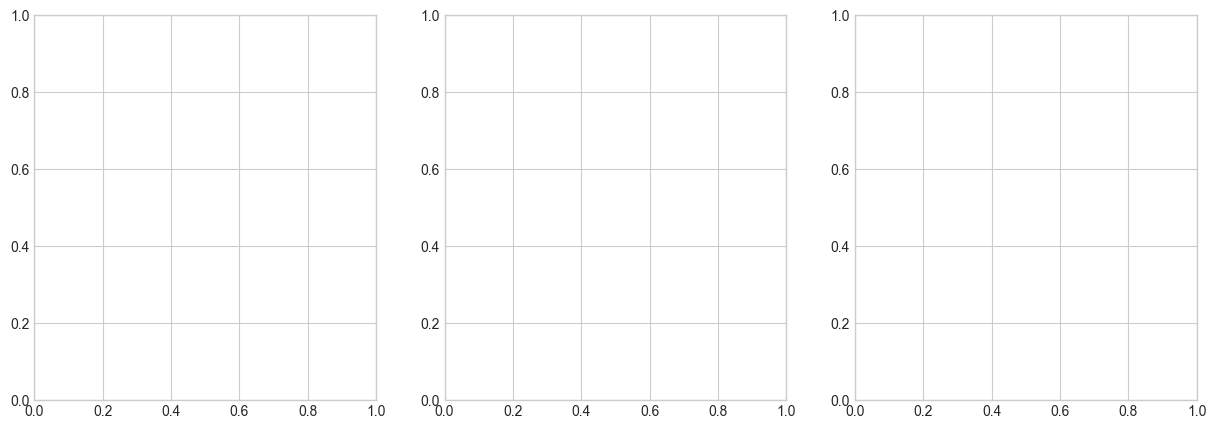

In [21]:
# %% [markdown]
# ## 12. Análisis de grupos usando factores

# %%
def analizar_grupos_por_factores(df, factores, var_grupo='ST004D01T', nombre_grupo='Género'):
    """
    Analiza diferencias en factores por grupos (género, NSE, etc.)
    """
    if var_grupo not in df.columns:
        print(f"⚠️ Variable {var_grupo} no encontrada")
        return None
    
    print(f"\n{'='*80}")
    print(f"ANÁLISIS POR {nombre_grupo.upper()}")
    print(f"{'='*80}")
    
    # Recodificar género si es necesario
    if var_grupo == 'ST004D01T':
        df['Grupo'] = df[var_grupo].map({1: 'Mujer', 2: 'Hombre'})
    else:
        df['Grupo'] = df[var_grupo]
    
    # Estadísticas por grupo
    print(f"\n📊 Promedios de factores por {nombre_grupo}:\n")
    
    resultados = []
    for factor in factores:
        if factor in df.columns:
            stats_grupo = df.groupby('Grupo')[factor].agg(['mean', 'std', 'count'])
            print(f"\n{factor}:")
            print(stats_grupo)
            
            # Test t para diferencias
            grupos = df['Grupo'].unique()
            if len(grupos) == 2:
                grupo1 = df[df['Grupo'] == grupos[0]][factor].dropna()
                grupo2 = df[df['Grupo'] == grupos[1]][factor].dropna()
                
                if len(grupo1) > 0 and len(grupo2) > 0:
                    t_stat, p_val = stats.ttest_ind(grupo1, grupo2)
                    
                    print(f"   t-test: t={t_stat:.3f}, p={p_val:.4f}")
                    if p_val < 0.05:
                        print(f"   ✓ Diferencia significativa (p < 0.05)")
                    else:
                        print(f"   ✗ No hay diferencia significativa")
                    
                    resultados.append({
                        'Factor': factor,
                        'Diferencia': abs(grupo1.mean() - grupo2.mean()),
                        'p-valor': p_val,
                        'Significativa': p_val < 0.05
                    })
    
    # Visualización
    if len(factores) > 0:
        df_plot = df[['Grupo'] + [f for f in factores if f in df.columns]].dropna()
        
        n_factores_plot = len([f for f in factores if f in df.columns])
        fig, axes = plt.subplots(1, min(3, n_factores_plot), figsize=(15, 5))
        if n_factores_plot == 1:
            axes = [axes]
        
        for idx, factor in enumerate(factores[:3]):
            if factor in df.columns and idx < len(axes):
                df_plot.boxplot(column=factor, by='Grupo', ax=axes[idx])
                axes[idx].set_title(f'{factor} por {nombre_grupo}')
                axes[idx].set_xlabel('')
                axes[idx].set_ylabel(factor)
                plt.suptitle('')
        
        plt.tight_layout()
        plt.show()
    
    return pd.DataFrame(resultados) if resultados else None

# Analizar por género si está disponible
if 'ST004D01T' in df.columns:
    analisis_genero = analizar_grupos_por_factores(
        df, factores_extraidos, 'ST004D01T', 'Género'
    )

# Analizar por cuartiles de NSE si ESCS está disponible
if 'ESCS' in df.columns:
    print(f"\n{'='*80}")
    print("ANÁLISIS POR NIVEL SOCIOECONÓMICO (ESCS)")
    print(f"{'='*80}")
    
    # Crear cuartiles
    df['ESCS_Cuartil'] = pd.qcut(df['ESCS'], q=4, labels=['Q1-Bajo', 'Q2', 'Q3', 'Q4-Alto'])
    
    print(f"\n📊 Promedios de factores por cuartil NSE:\n")
    
    for factor in factores_extraidos:
        if factor in df.columns:
            print(f"\n{factor}:")
            stats_nse = df.groupby('ESCS_Cuartil')[factor].agg(['mean', 'std', 'count'])
            print(stats_nse)
    
    # Visualización
    fig, axes = plt.subplots(1, min(3, len(factores_extraidos)), figsize=(15, 5))
    if len(factores_extraidos) == 1:
        axes = [axes]
    
    for idx, factor in enumerate(factores_extraidos[:3]):
        if factor in df.columns and idx < len(axes):
            df.boxplot(column=factor, by='ESCS_Cuartil', ax=axes[idx])
            axes[idx].set_title(f'{factor} por NSE')
            axes[idx].set_xlabel('Cuartil Socioeconómico')
            axes[idx].set_ylabel(factor)
            axes[idx].set_xticklabels(axes[idx].get_xticklabels(), rotation=45)
            plt.suptitle('')
    
    plt.tight_layout()
    plt.show()

In [22]:
# %% [markdown]
# ## 13. Recomendaciones finales para LCA e IRT

# %%
print("\n" + "="*80)
print("RECOMENDACIONES FINALES PARA MODELADO")
print("="*80)

print("""
📋 PARA LCA (LATENT CLASS ANALYSIS):
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

✅ VARIABLES RECOMENDADAS:

Opción recomendada: Usar FACTORES extraídos
   Ventajas:
   • Reduce dimensionalidad (menos variables, más interpretable)
   • Captura estructura latente de los datos
   • Reduce colinealidad entre variables
   
   Variables a usar:""")

for factor in factores_extraidos:
    print(f"   • {factor}")

print(f"""
   Librerías en Python:
   • sklearn-learn: GaussianMixture (para variables continuas)
   • poLCA en R (más común)
   
   Ejemplo de código:
   ```python
   from sklearn.mixture import GaussianMixture
   
   # Seleccionar factores
   X = df[{factores_extraidos}].dropna()
   
   # Probar diferentes números de clases
   for n_classes in range(2, 7):
       lca = GaussianMixture(n_components=n_classes, random_state=42)
       lca.fit(X)
       bic = lca.bic(X)
       print(f"Clases: {n_classes}, BIC: {bic:.2f}")
   ```

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

📋 PARA IRT (ITEM RESPONSE THEORY):
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

⚠️ IMPORTANTE: IRT requiere ÍTEMS originales, NO índices agregados

Pasos necesarios:

1️⃣ Identificar ítems del cuestionario:
   • Respuestas a preguntas específicas (ST001Q01, ST002Q01, etc.)
   • NO usar ESCS, HOMEPOS (son índices ya calculados por PISA)
   • Verificar que tienes las respuestas originales

2️⃣ Verificar tipo de ítem:
   • Dicotómicos (0/1): Modelos 1PL (Rasch), 2PL, 3PL
   • Ordinales (Likert 1-4): Graded Response Model (GRM)
   • Nominales: Nominal Response Model

3️⃣ Verificar unidimensionalidad:
   • Cada escala debe medir UN solo constructo
   • Usar el EFA de este notebook para verificar
   • Primer factor debe explicar >20% de varianza

4️⃣ Librerías recomendadas:
   Python:
   • py-irt: Para modelos básicos
   • mirt (via rpy2): Interfaz a librería R
   
   R (más maduro para IRT):
   • mirt: Multidimensional IRT
   • ltm: Latent Trait Models
   • TAM: Test Analysis Modules

   Ejemplo en Python:
   ```python
   from pyirt import irt
   
   # Preparar datos (personas × ítems)
   # Valores: 0/1 para dicotómicos, 0-k para ordinales
   item_data = df[items_list].dropna()
   
   # Ajustar modelo 2PL
   item_param, person_param = irt(item_data, 
                                   model='2PL',
                                   num_dim=1)
   ```

5️⃣ ⚠️ CRÍTICO para PISA:
   • PISA ya usa IRT internamente (Plausible Values)
   • Si quieres crear tus propias escalas → Usa ítems originales
   • Si usas PV existentes → NO necesitas IRT adicional

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

📊 DECISIÓN ESTRATÉGICA:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

¿Qué hacer con tus datos?

SI tienes ítems originales del cuestionario:
   → LCA: Usa factores extraídos o variables de alta comunalidad
   → IRT: Usa ítems originales agrupados por constructo

SI solo tienes índices agregados (ESCS, HOMEPOS, PV):
   → LCA: Usa factores extraídos (RECOMENDADO)
   → IRT: NO es apropiado (ya PISA aplicó IRT)
          → Usa los Plausible Values directamente

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
""")


RECOMENDACIONES FINALES PARA MODELADO

📋 PARA LCA (LATENT CLASS ANALYSIS):
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

✅ VARIABLES RECOMENDADAS:

Opción recomendada: Usar FACTORES extraídos
   Ventajas:
   • Reduce dimensionalidad (menos variables, más interpretable)
   • Captura estructura latente de los datos
   • Reduce colinealidad entre variables

   Variables a usar:
   • Factor_1
   • Factor_2
   • Factor_3
   • Factor_4
   • Factor_5
   • Factor_6
   • Factor_7
   • Factor_8


NameError: name 'n_classes' is not defined

In [23]:
# %% [markdown]
# ## 14. Checklist final

# %%
print("\n" + "="*80)
print("CHECKLIST FINAL - ¿ESTÁS LISTO PARA MODELAR?")
print("="*80)

checklist = {
    'Dataset con factores exportado': os.path.exists(f'{output_dir}/dataset_con_factores.csv'),
    'Supuestos EFA verificados (KMO, Bartlett)': resultados_supuestos['kmo_ok'] and resultados_supuestos['bartlett_ok'],
    'Factores extraídos e interpretados': len(factores_extraidos) > 0,
    'Cargas factoriales guardadas': os.path.exists(f'{output_dir}/cargas_factoriales.csv'),
    'Variables para LCA identificadas': len(selecciones_lca['factores']) > 0,
    'Correlaciones con rendimiento analizadas': correlaciones_factores is not None,
}

print("\n✅ Verificación:")
for item, completo in checklist.items():
    simbolo = "✅" if completo else "❌"
    print(f"   {simbolo} {item}")

todo_listo = all(checklist.values())

if todo_listo:
    print("\n" + "="*80)
    print("🎉 ¡ANÁLISIS EXPLORATORIO Y EFA COMPLETADO!")
    print("="*80)
    print("\n✅ Estás listo para:")
    print("   1. Ejecutar LCA con los factores extraídos")
    print("   2. Preparar ítems para IRT (si tienes respuestas originales)")
    print("   3. Validar modelos y analizar resultados")
    print("\n📁 Archivos generados en: ./{}/".format(output_dir))
    print("\n🚀 Próximo paso: Modelado LCA/IRT")
else:
    print("\n⚠️ Hay pasos pendientes. Revisa el checklist.")


CHECKLIST FINAL - ¿ESTÁS LISTO PARA MODELAR?

✅ Verificación:
   ✅ Dataset con factores exportado
   ❌ Supuestos EFA verificados (KMO, Bartlett)
   ✅ Factores extraídos e interpretados
   ✅ Cargas factoriales guardadas
   ✅ Variables para LCA identificadas
   ✅ Correlaciones con rendimiento analizadas

⚠️ Hay pasos pendientes. Revisa el checklist.



DETERMINACIÓN DEL NÚMERO ÓPTIMO DE FACTORES

1️⃣ CRITERIO DE KAISER (Eigenvalue > 1)
   Número de factores sugerido: 8
   Varianza explicada: 73.8%

   Primeros 10 eigenvalues:
      Factor 1: 2.789 (15.5% var, 15.5% acum)
      Factor 2: 2.468 (13.7% var, 29.2% acum)
      Factor 3: 1.846 (10.3% var, 39.5% acum)
      Factor 4: 1.782 (9.9% var, 49.4% acum)
      Factor 5: 1.164 (6.5% var, 55.8% acum)
      Factor 6: 1.119 (6.2% var, 62.0% acum)
      Factor 7: 1.107 (6.1% var, 68.2% acum)
      Factor 8: 1.009 (5.6% var, 73.8% acum)
      Factor 9: 0.991 (5.5% var, 79.3% acum)
      Factor 10: 0.866 (4.8% var, 84.1% acum)

2️⃣ CRITERIO DE VARIANZA EXPLICADA
   Factores para 70% varianza: 8
   Factores para 80% varianza: 10

3️⃣ SCREE PLOT (Gráfico de sedimentación)


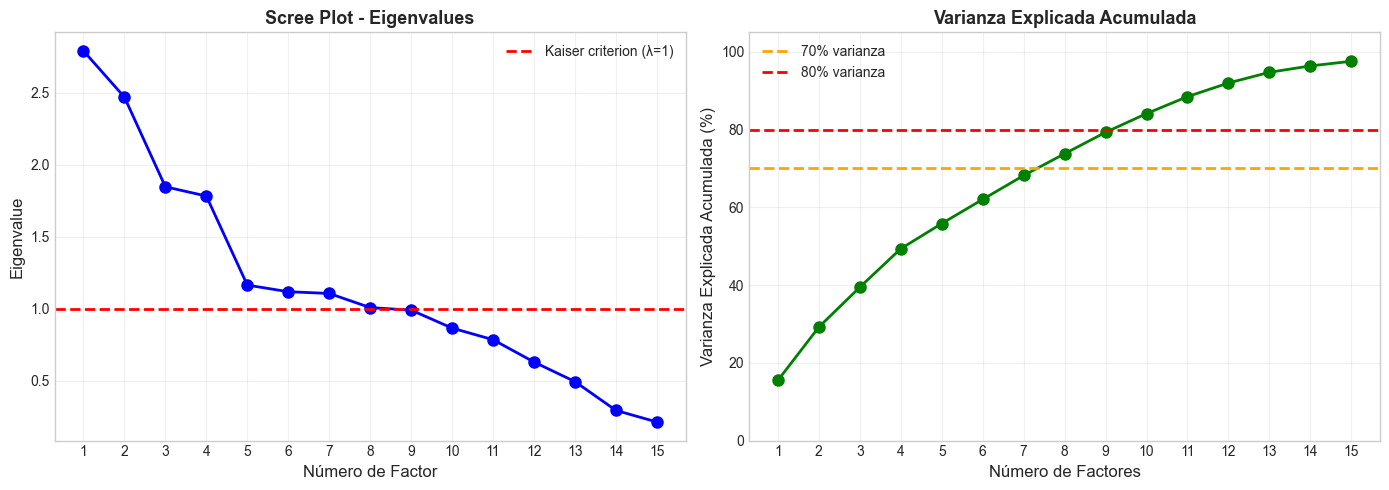

   → Busca el 'codo' donde los eigenvalues empiezan a aplanarse

4️⃣ ANÁLISIS PARALELO
   Comparando eigenvalues reales vs datos aleatorios...
   Factores sugeridos: 7


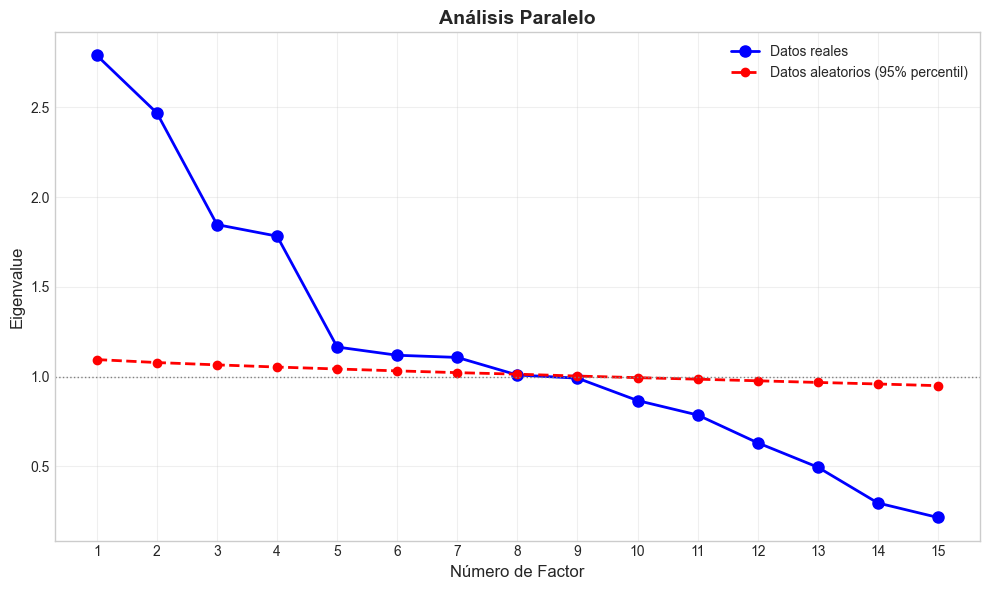


RECOMENDACIÓN FINAL

📊 Resumen de criterios:
   • Kaiser (λ > 1): 8 factores
   • Varianza 70%: 8 factores
   • Varianza 80%: 10 factores
   • Análisis Paralelo: 7 factores

✅ NÚMERO RECOMENDADO: 8 factores
   (mediana de los criterios)

💡 INTERPRETACIÓN:
   → Estructura factorial compleja (>6 factores)
   → Considera reducir número de variables o factores

EXTRACCIÓN DE 8 FACTORES

→ Extrayendo 8 factores...
✓ Factores extraídos exitosamente

CARGAS FACTORIALES

Cargas factoriales significativas (|carga| > 0.3):


Factor_1:
  ESCS                          :  1.022 +++
  HOMEPOS                       :  0.755 +++
  HISEI                         :  0.733 +++

Factor_2:
  CM033Q01TT                    :  0.956 +++
  CM033Q01F                     :  0.789 +++

Factor_3:
  CM155Q02TT                    :  0.859 +++
  CM155Q02A                     :  0.707 +++
  CM155Q02V                     :  0.373 +

Factor_4:
  CM155Q01TT                    :  0.858 +++
  CM155Q01A                     

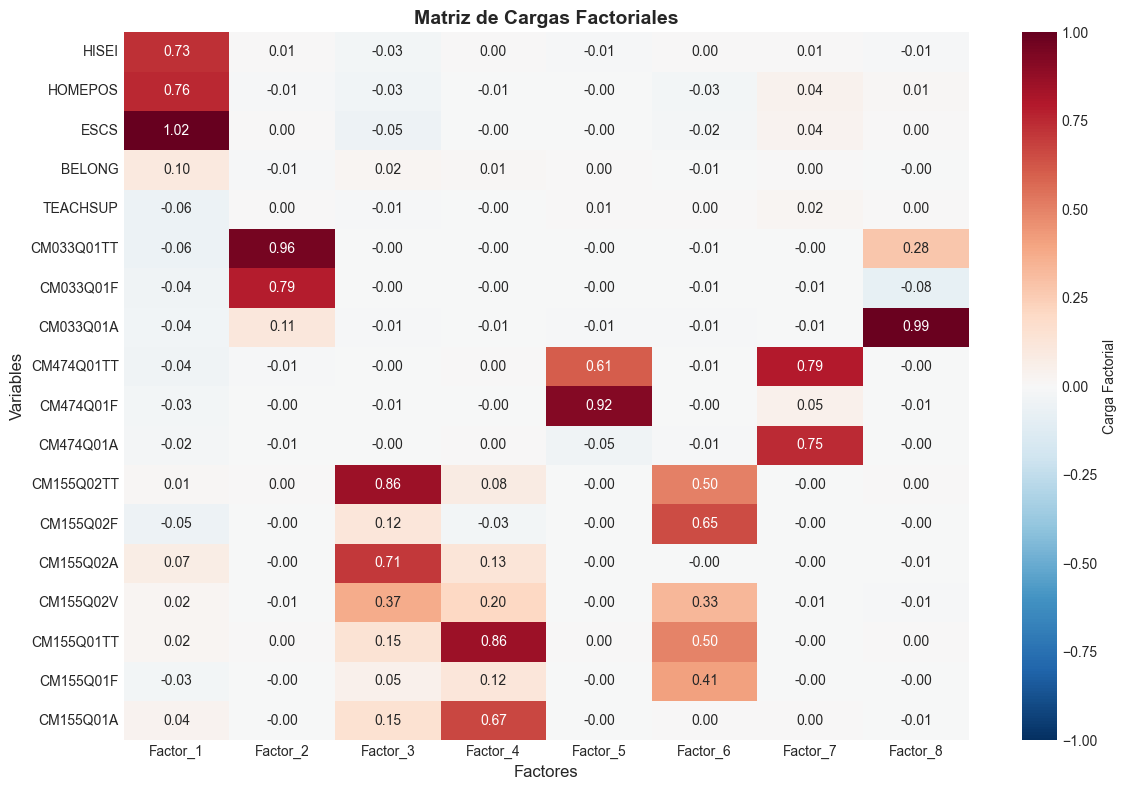


INTERPRETACIÓN DE FACTORES

Factor_1:
  Variable dominante: ESCS (carga: 1.022)
  Variables importantes (carga > 0.4): 3
    • ESCS: 1.022
    • HOMEPOS: 0.755
    • HISEI: 0.733

Factor_2:
  Variable dominante: CM033Q01TT (carga: 0.956)
  Variables importantes (carga > 0.4): 2
    • CM033Q01TT: 0.956
    • CM033Q01F: 0.789

Factor_3:
  Variable dominante: CM155Q02TT (carga: 0.859)
  Variables importantes (carga > 0.4): 2
    • CM155Q02TT: 0.859
    • CM155Q02A: 0.707

Factor_4:
  Variable dominante: CM155Q01TT (carga: 0.858)
  Variables importantes (carga > 0.4): 2
    • CM155Q01TT: 0.858
    • CM155Q01A: 0.669

Factor_5:
  Variable dominante: CM474Q01F (carga: 0.921)
  Variables importantes (carga > 0.4): 2
    • CM474Q01F: 0.921
    • CM474Q01TT: 0.609

Factor_6:
  Variable dominante: CM155Q02F (carga: 0.650)
  Variables importantes (carga > 0.4): 4
    • CM155Q02F: 0.650
    • CM155Q02TT: 0.502
    • CM155Q01TT: 0.500
    • CM155Q01F: 0.412

Factor_7:
  Variable dominante: CM474Q0

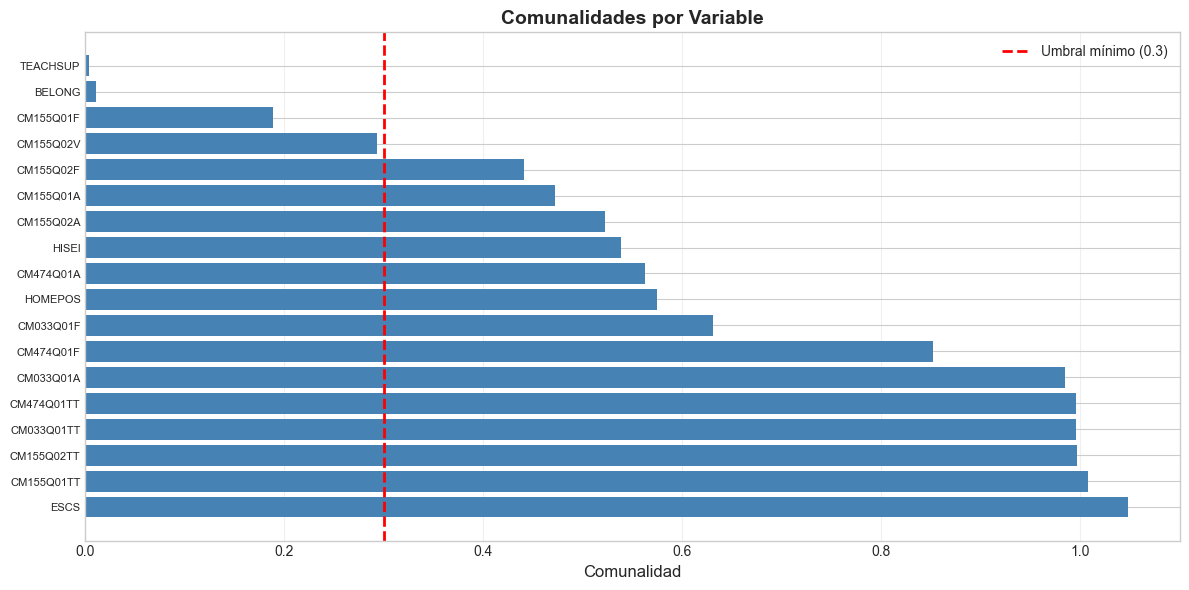


PUNTUACIONES FACTORIALES

✓ Calculadas puntuaciones factoriales para 6968 observaciones

Primeras 5 observaciones:
   Factor_1  Factor_2  Factor_3  Factor_4  Factor_5  Factor_6  Factor_7  \
0 -0.679188 -0.079194 -0.047632 -0.022045 -0.083112 -0.043000 -0.085928   
1 -0.268212 -0.063179 -0.060795 -0.024202  3.632541 -0.022372  2.062761   
2 -1.285460 -0.110807 -0.013565  0.003297 -0.101249 -0.080953 -0.101609   
3 -2.232035 -0.153316  0.013394  0.053806 -0.117372 -0.080036 -0.149682   
4  1.025158  0.011979 -0.106316 -0.087619 -0.042099  0.028731 -0.030074   

   Factor_8  
0 -0.166524  
1 -0.106149  
2 -0.183414  
3 -0.217566  
4 -0.113139  

Estadísticas de los factores:
           Factor_1      Factor_2      Factor_3      Factor_4      Factor_5  \
count  6.968000e+03  6.968000e+03  6.968000e+03  6.968000e+03  6.968000e+03   
mean  -1.264456e-16 -1.509190e-16  4.078891e-17 -1.182878e-16 -1.968065e-16   
std    1.046811e+00  9.970161e-01  9.548271e-01  9.665430e-01  9.330804e-01   
mi

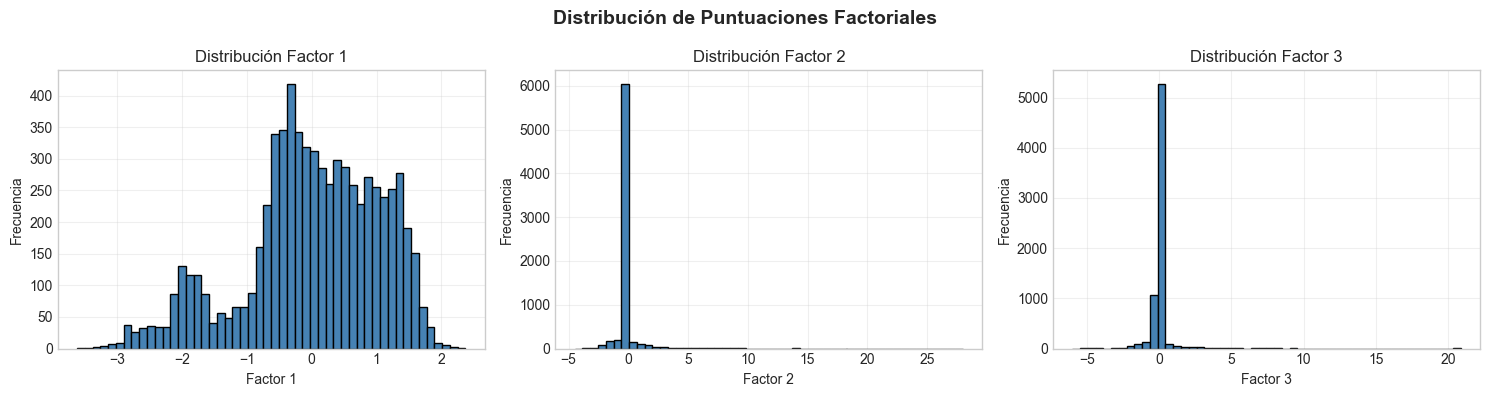


✓ Puntuaciones factoriales agregadas al dataset principal
  Nuevas columnas: ['Factor_1', 'Factor_2', 'Factor_3', 'Factor_4', 'Factor_5', 'Factor_6', 'Factor_7', 'Factor_8']

GUÍA PARA INTERPRETAR Y NOMBRAR FACTORES

Para cada factor, identifica:

1. ¿Qué variables tienen las cargas más altas (>0.4)?
2. ¿Qué tienen en común conceptualmente estas variables?
3. ¿Qué constructo latente representan?

Ejemplos de factores comunes en PISA:

• Factor Socioeconómico:
  - ESCS, HOMEPOS, WEALTH, CULTPOSS
  - Representa el estatus socioeconómico familiar

• Factor de Recursos Educativos:
  - HEDRES, libros en casa, acceso a tecnología
  - Representa recursos para el aprendizaje

• Factor Motivacional:
  - MOTIVAT, JOYREAD, actitudes hacia el estudio
  - Representa motivación intrínseca

• Factor de Clima Escolar:
  - DISCLIMA, TEACHSUP, BELONG
  - Representa ambiente de aprendizaje

Ahora analiza TUS factores con las cargas mostradas arriba.


📝 NOMBRA TUS FACTORES:

Factor_1:
  Variables princi

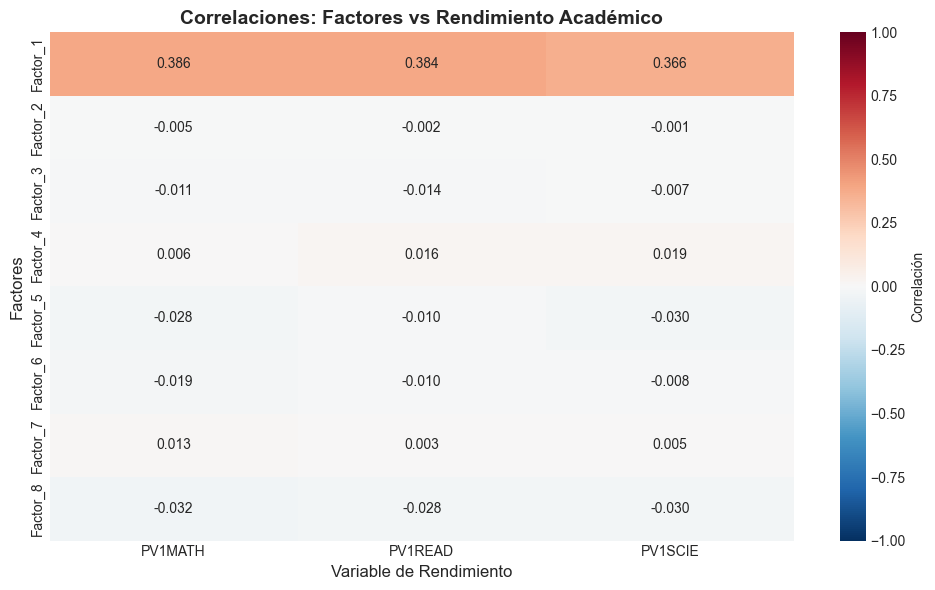


📊 FACTORES MÁS PREDICTIVOS DEL RENDIMIENTO:
  Factor_1: r_promedio = 0.379 (±0.011)
  Factor_4: r_promedio = 0.014 (±0.007)
  Factor_7: r_promedio = 0.007 (±0.005)
  Factor_2: r_promedio = -0.003 (±0.002)
  Factor_3: r_promedio = -0.011 (±0.003)
  Factor_6: r_promedio = -0.012 (±0.006)
  Factor_5: r_promedio = -0.023 (±0.011)
  Factor_8: r_promedio = -0.030 (±0.002)

SELECCIÓN DE VARIABLES PARA LCA (Latent Class Analysis)

Con base en el EFA, puedes seleccionar variables para LCA de dos formas:

OPCIÓN 1: Usar las puntuaciones factoriales
   • Ventaja: Reduce dimensionalidad drásticamente
   • Usa los factores como variables continuas en LCA
   • Ejemplo: Si tienes 3 factores, LCA trabajará con 3 variables

OPCIÓN 2: Usar variables originales bien representadas
   • Toma variables con alta comunalidad (>0.5)
   • Selecciona las más representativas de cada factor
   • Mantiene interpretabilidad de variables originales

OPCIÓN 3: Híbrido
   • Factores + algunas variables clave originale

ValueError: could not convert string to float: 'Grade 9'

In [ ]:
# %% [markdown]
# ## 15. Código de plantilla para siguiente paso

# %%
print("\n" + "="*80)
print("PLANTILLA DE CÓDIGO PARA LCA")
print("="*80)

codigo_lca = f"""
# ===================================================================
# ANÁLISIS DE CLASES LATENTES (LCA) con Factores del EFA
# ===================================================================

import pandas as pd
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar datos con factores
df = pd.read_csv('resultados_efa/dataset_con_factores.csv')

# 2. Seleccionar factores para LCA
factores = {factores_extraidos}

X = df[factores].dropna()
print(f"Observaciones para LCA: {{len(X):,}}")

# 3. Estandarizar (opcional pero recomendado)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Probar diferentes números de clases (2-6)
resultados_lca = []

for n_classes in range(2, 7):
    lca = GaussianMixture(
        n_components=n_classes,
        covariance_type='full',  # o 'tied', 'diag', 'spherical'
        random_state=42,
        n_init=10
    )
    
    lca.fit(X_scaled)
    
    # Métricas de ajuste
    bic = lca.bic(X_scaled)
    aic = lca.aic(X_scaled)
    log_likelihood = lca.score(X_scaled) * len(X_scaled)
    
    resultados_lca.append({{
        'N_Clases': n_classes,
        'BIC': bic,
        'AIC': aic,
        'Log-Likelihood': log_likelihood
    }})
    
    print(f"Clases: {{n_classes}}, BIC: {{bic:.2f}}, AIC: {{aic:.2f}}")

# 5. Seleccionar modelo óptimo (menor BIC)
df_resultados = pd.DataFrame(resultados_lca)
mejor_n = df_resultados.loc[df_resultados['BIC'].idxmin(), 'N_Clases']

print(f"\\n✓ Número óptimo de clases: {{int(mejor_n)}}")

# 6. Ajustar modelo final
lca_final = GaussianMixture(
    n_components=int(mejor_n),
    covariance_type='full',
    random_state=42,
    n_init=20
)

lca_final.fit(X_scaled)

# 7. Asignar clases
df['Clase_Latente'] = lca_final.predict(X_scaled)
df['Probabilidad_Clase'] = lca_final.predict_proba(X_scaled).max(axis=1)

# 8. Caracterizar clases
print("\\nPerfil de clases:")
print(df.groupby('Clase_Latente')[factores].mean())

# 9. Guardar resultados
df.to_csv('resultados_lca_final.csv', index=False)
"""

print(codigo_lca)

print("\n💾 Código guardado en: codigo_plantilla_lca.py")
with open('codigo_plantilla_lca.py', 'w') as f:
    f.write(codigo_lca)

# %%
print("\n" + "="*80)
print("✅ NOTEBOOK COMPLETADO")
print("="*80)
print("\nHas completado:")
print("  ✓ Análisis exploratorio de datos")
print("  ✓ Análisis Factorial Exploratorio (EFA)")
print("  ✓ Reducción de dimensionalidad")
print("  ✓ Identificación de variables latentes")
print("  ✓ Preparación para LCA e IRT")
print("\n🎯 Siguiente paso: Ejecutar LCA con los factores o preparar IRT con ítems")
print("="*80)

# %% [markdown]
# # Análisis Exploratorio Profundo + Análisis Factorial Exploratorio (EFA)
# ## PISA 2022 - Preparación para LCA e IRT
# 
# **Objetivos de este notebook:**
# 1. Análisis descriptivo completo del dataset final
# 2. Análisis de correlaciones y relaciones entre variables
# 3. **Análisis Factorial Exploratorio (EFA) para reducción de dimensionalidad**
# 4. Identificación de variables latentes
# 5. Selección de variables para LCA
# 6. Preparación de ítems para IRT
# 7. Verificación de supuestos
#
# **Pre-requisito:**
# - Dataset final con imputación completada (mediana o MICE)

# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, pearsonr, spearmanr
import warnings
warnings.filterwarnings('ignore')

# Para Análisis Factorial
from sklearn.decomposition import FactorAnalysis, PCA
from sklearn.preprocessing import StandardScaler
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo

print("✓ Librerías cargadas")

# Si no tienes factor_analyzer:
# !pip install factor-analyzer

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10

# %% [markdown]
# ## 1. Cargar dataset final

# %%
# Cargar tu dataset final (ajusta el nombre)
df = pd.read_csv('dataset_limpio_final.csv')  # O dataset_imputado_mice.csv

print("="*80)
print("DATASET CARGADO")
print("="*80)
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"Memoria: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

# Verificar datos faltantes
missing_total = df.isna().sum().sum()
if missing_total > 0:
    print(f"⚠️ Aún hay {missing_total:,} valores faltantes")
else:
    print(f"✓ Dataset completamente imputado")

# Tipos de variables
print(f"\nTipos de variables:")
print(f"  Numéricas: {len(df.select_dtypes(include=[np.number]).columns)}")
print(f"  Categóricas: {len(df.select_dtypes(include=['object', 'category']).columns)}")

# %% [markdown]
# ## 2. Identificar variables clave automáticamente

# %%
def identificar_variables_pisa(df):
    """
    Identifica automáticamente variables clave de PISA
    """
    variables = {
        'ids': [],
        'pesos': [],
        'rendimiento': [],
        'socioeconomico': [],
        'demograficas': [],
        'actitudes': [],
        'escuela': [],
        'otras_numericas': [],
        'categoricas': []
    }
    
    # Patrones de búsqueda
    patrones = {
        'ids': ['CNTRYID', 'CNTSCHID', 'CNTSTUID', 'CNT'],
        'pesos': ['W_FSTUWT', 'WEIGHT', 'W_FST'],
        'rendimiento': ['PV1MATH', 'PV1READ', 'PV1SCIE', 'PV2', 'PV3', 'PV4', 'PV5'],
        'socioeconomico': ['ESCS', 'HOMEPOS', 'WEALTH', 'CULTPOSS', 'HEDRES', 'HISEI'],
        'demograficas': ['ST004D01T', 'GENDER', 'AGE', 'GRADE', 'IMMIG'],
        'actitudes': ['ANXTEST', 'MOTIVAT', 'BELONG', 'TEACHSUP', 'DISCLIMA', 'JOYREAD'],
        'escuela': ['SCHSIZE', 'STRATIO', 'SCHTYPE', 'CLSIZE', 'SC']
    }
    
    # Clasificar columnas
    for col in df.columns:
        col_upper = col.upper()
        clasificada = False
        
        for categoria, patterns in patrones.items():
            if any(pattern in col_upper for pattern in patterns):
                variables[categoria].append(col)
                clasificada = True
                break
        
        if not clasificada:
            if df[col].dtype in ['float64', 'int64']:
                variables['otras_numericas'].append(col)
            else:
                variables['categoricas'].append(col)
    
    return variables

vars_clasificadas = identificar_variables_pisa(df)

print("\n" + "="*80)
print("CLASIFICACIÓN AUTOMÁTICA DE VARIABLES")
print("="*80)

for categoria, vars_list in vars_clasificadas.items():
    if len(vars_list) > 0:
        print(f"\n{categoria.upper()}: {len(vars_list)} variables")
        print(f"  Primeras 5: {vars_list[:5]}")

# %% [markdown]
# ## 3. Estadísticas descriptivas completas

# %%
def estadisticas_completas(df, variables):
    """
    Genera estadísticas descriptivas completas
    """
    if len(variables) == 0:
        print("⚠️ No hay variables para analizar")
        return None
    
    # Filtrar solo numéricas
    vars_numericas = [v for v in variables if v in df.columns and df[v].dtype in ['float64', 'int64']]
    
    if len(vars_numericas) == 0:
        print("⚠️ No hay variables numéricas")
        return None
    
    stats_dict = {
        'Variable': [],
        'N': [],
        'N_Missing': [],
        'Pct_Missing': [],
        'Media': [],
        'Mediana': [],
        'DE': [],
        'CV': [],
        'Min': [],
        'Q1': [],
        'Q3': [],
        'Max': [],
        'Rango': [],
        'IQR': [],
        'Asimetría': [],
        'Curtosis': []
    }
    
    for var in vars_numericas[:50]:  # Limitar a 50 para no saturar
        data = df[var]
        data_clean = data.dropna()
        
        if len(data_clean) > 0:
            stats_dict['Variable'].append(var)
            stats_dict['N'].append(len(data_clean))
            stats_dict['N_Missing'].append(data.isna().sum())
            stats_dict['Pct_Missing'].append(data.isna().sum() / len(data) * 100)
            stats_dict['Media'].append(data_clean.mean())
            stats_dict['Mediana'].append(data_clean.median())
            stats_dict['DE'].append(data_clean.std())
            stats_dict['CV'].append(data_clean.std() / abs(data_clean.mean()) if data_clean.mean() != 0 else np.nan)
            stats_dict['Min'].append(data_clean.min())
            stats_dict['Q1'].append(data_clean.quantile(0.25))
            stats_dict['Q3'].append(data_clean.quantile(0.75))
            stats_dict['Max'].append(data_clean.max())
            stats_dict['Rango'].append(data_clean.max() - data_clean.min())
            stats_dict['IQR'].append(data_clean.quantile(0.75) - data_clean.quantile(0.25))
            stats_dict['Asimetría'].append(data_clean.skew())
            stats_dict['Curtosis'].append(data_clean.kurtosis())
    
    return pd.DataFrame(stats_dict)

# Estadísticas de rendimiento
print("\n" + "="*80)
print("ESTADÍSTICAS DESCRIPTIVAS - VARIABLES DE RENDIMIENTO")
print("="*80)

if len(vars_clasificadas['rendimiento']) > 0:
    stats_rendimiento = estadisticas_completas(df, vars_clasificadas['rendimiento'])
    if stats_rendimiento is not None:
        print(stats_rendimiento[['Variable', 'N', 'Media', 'DE', 'Min', 'Max']].to_string(index=False))
else:
    print("⚠️ No se encontraron variables de rendimiento")

# Estadísticas socioeconómicas
print("\n" + "="*80)
print("ESTADÍSTICAS DESCRIPTIVAS - VARIABLES SOCIOECONÓMICAS")
print("="*80)

if len(vars_clasificadas['socioeconomico']) > 0:
    stats_nse = estadisticas_completas(df, vars_clasificadas['socioeconomico'])
    if stats_nse is not None:
        print(stats_nse[['Variable', 'N', 'Media', 'DE', 'Min', 'Max']].to_string(index=False))

# %% [markdown]
# ## 4. Visualización de distribuciones

# %%
def visualizar_distribuciones(df, variables, titulo="Distribuciones"):
    """
    Visualiza distribuciones de variables
    """
    # Filtrar numéricas
    vars_plot = [v for v in variables if v in df.columns and df[v].dtype in ['float64', 'int64']]
    vars_plot = vars_plot[:9]  # Máximo 9 para visualización 3x3
    
    if len(vars_plot) == 0:
        print("⚠️ No hay variables numéricas para graficar")
        return
    
    n_vars = len(vars_plot)
    n_cols = 3
    n_rows = (n_vars + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows))
    if n_vars == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    
    for idx, var in enumerate(vars_plot):
        data = df[var].dropna()
        
        if len(data) > 0:
            # Histograma con curva de densidad
            axes[idx].hist(data, bins=50, alpha=0.7, color='steelblue', 
                          edgecolor='black', density=True)
            
            # Líneas de referencia
            mean_val = data.mean()
            median_val = data.median()
            
            axes[idx].axvline(mean_val, color='red', linestyle='--', 
                             linewidth=2, label=f'Media: {mean_val:.1f}')
            axes[idx].axvline(median_val, color='green', linestyle='--',
                             linewidth=2, label=f'Mediana: {median_val:.1f}')
            
            axes[idx].set_title(f'{var}\n(n={len(data):,}, DE={data.std():.1f})', 
                               fontsize=10, fontweight='bold')
            axes[idx].set_xlabel('Valor')
            axes[idx].set_ylabel('Densidad')
            axes[idx].legend(fontsize=8)
            axes[idx].grid(alpha=0.3)
    
    # Ocultar ejes sobrantes
    for idx in range(n_vars, len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle(titulo, fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

# Visualizar rendimiento
if len(vars_clasificadas['rendimiento']) > 0:
    visualizar_distribuciones(df, vars_clasificadas['rendimiento'][:9], 
                             "Distribuciones - Variables de Rendimiento")

# Visualizar socioeconómicas
if len(vars_clasificadas['socioeconomico']) > 0:
    visualizar_distribuciones(df, vars_clasificadas['socioeconomico'][:9],
                             "Distribuciones - Variables Socioeconómicas")

# %% [markdown]
# ## 5. ANÁLISIS FACTORIAL EXPLORATORIO (EFA)
# ### 5.1. Preparación de datos para EFA

# %%
print("\n" + "="*80)
print("PREPARACIÓN PARA ANÁLISIS FACTORIAL EXPLORATORIO (EFA)")
print("="*80)

print("""
El EFA nos permite:
✓ Identificar variables latentes (factores)
✓ Reducir dimensionalidad
✓ Agrupar variables correlacionadas
✓ Preparar datos para IRT
✓ Entender estructura subyacente de los datos

Pasos:
1. Seleccionar variables apropiadas
2. Verificar supuestos (KMO, Bartlett)
3. Determinar número óptimo de factores
4. Extraer factores
5. Interpretar resultados
""")

def preparar_datos_efa(df, variables_candidatas, min_varianza=0.01):
    """
    Prepara datos para EFA
    
    Criterios:
    - Solo variables numéricas
    - Sin constantes (varianza > min_varianza)
    - Sin missing (ya deben estar imputadas)
    - Correlacionadas con al menos alguna otra variable
    """
    print("\n📊 Preparando datos para EFA...")
    
    # Filtrar numéricas
    vars_numericas = [v for v in variables_candidatas 
                      if v in df.columns and df[v].dtype in ['float64', 'int64']]
    
    print(f"   Variables numéricas iniciales: {len(vars_numericas)}")
    
    # Crear subset
    df_efa = df[vars_numericas].copy()
    
    # Eliminar variables constantes o casi constantes
    vars_validas = []
    for col in df_efa.columns:
        if df_efa[col].var() > min_varianza:
            vars_validas.append(col)
        else:
            print(f"   ⚠️ Eliminada {col}: varianza muy baja ({df_efa[col].var():.6f})")
    
    df_efa = df_efa[vars_validas]
    print(f"   Variables tras filtro de varianza: {len(df_efa.columns)}")
    
    # Verificar missing
    if df_efa.isna().sum().sum() > 0:
        print(f"   ⚠️ Hay {df_efa.isna().sum().sum()} valores faltantes")
        print("   Aplicando imputación de emergencia con mediana...")
        for col in df_efa.columns:
            if df_efa[col].isna().any():
                df_efa[col].fillna(df_efa[col].median(), inplace=True)
    
    print(f"\n✓ Dataset EFA preparado: {df_efa.shape}")
    
    return df_efa

# Seleccionar variables para EFA
# OPCIÓN 1: Usar variables socioeconómicas + actitudes (común en PISA)
vars_para_efa = (vars_clasificadas['socioeconomico'] + 
                 vars_clasificadas['actitudes'] + 
                 vars_clasificadas['otras_numericas'][:20])  # Agregar otras relevantes

# OPCIÓN 2: O definir manualmente variables de interés
# vars_para_efa = ['ESCS', 'HOMEPOS', 'WEALTH', 'CULTPOSS', ...]

print(f"\nVariables candidatas para EFA: {len(vars_para_efa)}")

df_efa = preparar_datos_efa(df, vars_para_efa)

# %% [markdown]
# ## 5.2. Verificación de supuestos para EFA

# %%
def verificar_supuestos_efa(df_efa):
    """
    Verifica supuestos necesarios para EFA:
    1. KMO (Kaiser-Meyer-Olkin): adecuación muestral
    2. Test de Bartlett: correlaciones significativas
    """
    print("\n" + "="*80)
    print("VERIFICACIÓN DE SUPUESTOS PARA EFA")
    print("="*80)
    
    # 1. Test de Bartlett
    print("\n1️⃣ TEST DE BARTLETT (esfericidad)")
    print("   H0: La matriz de correlación es una matriz identidad")
    print("   H1: Hay correlaciones significativas entre variables\n")
    
    try:
        chi_square_value, p_value = calculate_bartlett_sphericity(df_efa)
        print(f"   Chi-cuadrado: {chi_square_value:.2f}")
        print(f"   p-valor: {p_value:.2e}")
        
        if p_value < 0.05:
            print("   ✅ RESULTADO: Rechazamos H0 (p < 0.05)")
            print("      → Las variables están suficientemente correlacionadas")
            print("      → EFA es apropiado")
            bartlett_ok = True
        else:
            print("   ❌ RESULTADO: No rechazamos H0 (p >= 0.05)")
            print("      → Las variables NO están suficientemente correlacionadas")
            print("      → EFA NO es apropiado para estos datos")
            bartlett_ok = False
    except Exception as e:
        print(f"   ⚠️ Error en test de Bartlett: {e}")
        bartlett_ok = False
    
    # 2. KMO (Kaiser-Meyer-Olkin)
    print("\n2️⃣ ÍNDICE KMO (Kaiser-Meyer-Olkin)")
    print("   Mide la adecuación de los datos para análisis factorial\n")
    
    try:
        kmo_all, kmo_model = calculate_kmo(df_efa)
        
        print(f"   KMO global: {kmo_model:.3f}")
        
        # Interpretación
        if kmo_model >= 0.90:
            interpretacion = "Maravilloso"
            color = "✅"
        elif kmo_model >= 0.80:
            interpretacion = "Meritorio"
            color = "✅"
        elif kmo_model >= 0.70:
            interpretacion = "Mediano"
            color = "⚠️"
        elif kmo_model >= 0.60:
            interpretacion = "Mediocre"
            color = "⚠️"
        elif kmo_model >= 0.50:
            interpretacion = "Bajo"
            color = "❌"
        else:
            interpretacion = "Inaceptable"
            color = "❌"
        
        print(f"   {color} INTERPRETACIÓN: {interpretacion}")
        
        kmo_ok = kmo_model >= 0.60
        
        if kmo_ok:
            print("      → Los datos son adecuados para EFA")
        else:
            print("      → Los datos NO son adecuados para EFA")
            print("      → Considera eliminar variables problemáticas")
        
        # KMO por variable
        print(f"\n   Variables con KMO < 0.50 (problemáticas):")
        vars_problematicas = []
        for idx, (var, kmo_val) in enumerate(zip(df_efa.columns, kmo_all)):
            if kmo_val < 0.50:
                vars_problematicas.append(var)
                print(f"      • {var}: {kmo_val:.3f}")
        
        if len(vars_problematicas) == 0:
            print("      ✓ Ninguna variable es problemática")
        else:
            print(f"\n   ⚠️ Considera eliminar {len(vars_problematicas)} variables con KMO < 0.50")
        
    except Exception as e:
        print(f"   ⚠️ Error en cálculo de KMO: {e}")
        kmo_ok = False
        vars_problematicas = []
    
    # Resumen
    print("\n" + "="*80)
    print("RESUMEN DE SUPUESTOS:")
    print("="*80)
    print(f"   Test de Bartlett: {'✅ Apropiado' if bartlett_ok else '❌ No apropiado'}")
    print(f"   KMO global: {'✅ Adecuado' if kmo_ok else '❌ Inadecuado'} ({kmo_model:.3f})")
    
    if bartlett_ok and kmo_ok:
        print("\n   ✅ CONCLUSIÓN: Los datos son APROPIADOS para EFA")
        print("      → Puedes continuar con el análisis factorial")
    else:
        print("\n   ❌ CONCLUSIÓN: Los datos tienen problemas para EFA")
        print("      → Opciones:")
        print("        1. Eliminar variables problemáticas")
        print("        2. Seleccionar otro conjunto de variables")
        print("        3. Revisar la calidad de los datos")
    
    return {
        'bartlett_ok': bartlett_ok,
        'bartlett_p': p_value if 'p_value' in locals() else None,
        'kmo_ok': kmo_ok,
        'kmo_global': kmo_model if 'kmo_model' in locals() else None,
        'vars_problematicas': vars_problematicas if 'vars_problematicas' in locals() else []
    }

# Verificar supuestos
resultados_supuestos = verificar_supuestos_efa(df_efa)

# %% [markdown]
# ## 5.3. Eliminar variables problemáticas (si es necesario)

# %%
if len(resultados_supuestos.get('vars_problematicas', [])) > 0:
    print("\n" + "="*80)
    print("LIMPIEZA DE VARIABLES PROBLEMÁTICAS")
    print("="*80)
    
    respuesta = input(f"\n¿Eliminar {len(resultados_supuestos['vars_problematicas'])} variables con KMO < 0.50? (s/n): ")
    
    if respuesta.lower() == 's':
        df_efa_limpio = df_efa.drop(columns=resultados_supuestos['vars_problematicas'])
        print(f"\n✓ Variables eliminadas: {len(resultados_supuestos['vars_problematicas'])}")
        print(f"✓ Variables restantes: {len(df_efa_limpio.columns)}")
        
        # Re-verificar supuestos
        print("\n Reverificando supuestos con datos limpios...")
        resultados_supuestos_limpio = verificar_supuestos_efa(df_efa_limpio)
        
        # Actualizar dataset
        df_efa = df_efa_limpio
    else:
        print("\n⚠️ Continuando con todas las variables")
        print("   Los resultados de EFA pueden no ser óptimos")

# %%